# Bankruptcy Prediction — MF815 Machine Learning


In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
sns.set_theme(style='ticks', palette='muted')                              
sns.set_context('paper', font_scale=1.2)

# 1. EDA

In [94]:
train_raw = pd.read_csv('train.csv')
test_raw  = pd.read_csv('test.csv')

# Drop the row-index column if present
for df in [train_raw, test_raw]:
    unnamed = [c for c in df.columns if c.lower().startswith('unnamed')]
    if unnamed:
        df.drop(columns=unnamed, inplace=True)


print(f"Train shape: {train_raw.shape}  |  Test shape: {test_raw.shape}")
print(f"\nTarget: {'Bankrupt?' in train_raw.columns}")
print(f"\nTarget distribution:\n{train_raw['Bankrupt?'].value_counts()}")
    

Train shape: (5455, 96)  |  Test shape: (1364, 95)

Target: True

Target distribution:
Bankrupt?
0    5285
1     170
Name: count, dtype: int64


In [95]:
train_raw.info() #95 features + 1 target 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5455 entries, 0 to 5454
Data columns (total 96 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0    ROA(C) before interest and depreciation before interest  5455 non-null   float64
 1    ROA(A) before interest and % after tax                   5455 non-null   float64
 2    ROA(B) before interest and depreciation after tax        5455 non-null   float64
 3    Operating Gross Margin                                   5455 non-null   float64
 4    Realized Sales Gross Margin                              5455 non-null   float64
 5    Operating Profit Rate                                    5455 non-null   float64
 6    Pre-tax net Interest Rate                                5455 non-null   float64
 7    After-tax net Interest Rate                              5455 non-null   float64
 8    Non-industry inco

=== Target Distribution ===
  Class 0: 5,285  (96.88%)
  Class 1: 170  (3.12%)


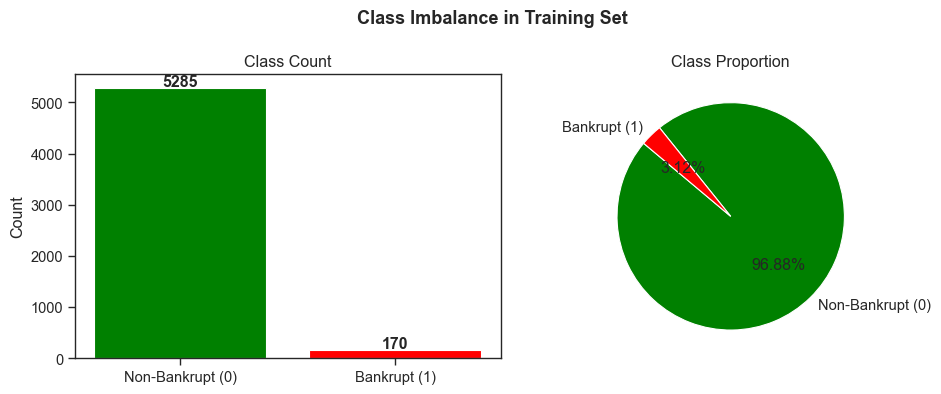


Imbalance ratio (0:1) ≈ 31.1:1  →  SMOTE or class_weight needed


In [96]:
counts = train_raw['Bankrupt?'].value_counts()
pct    = train_raw['Bankrupt?'].value_counts(normalize=True) * 100

print("=== Target Distribution ===")
for cls in [0, 1]:
    print(f"  Class {cls}: {counts[cls]:,}  ({pct[cls]:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Bar chart
axes[0].bar(['Non-Bankrupt (0)', 'Bankrupt (1)'], counts.values,
            color=['green', 'red'], edgecolor='white')
axes[0].set_title('Class Count')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, str(v), ha='center', fontweight='bold')

# Pie chart
axes[1].pie(counts.values, labels=['Non-Bankrupt (0)', 'Bankrupt (1)'],
            autopct='%1.2f%%', colors=['green', 'red'],
            startangle=140, wedgeprops=dict(edgecolor='white'))
axes[1].set_title('Class Proportion')

plt.suptitle('Class Imbalance in Training Set', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

imbalance_ratio = counts[0] / counts[1]
print(f"\nImbalance ratio (0:1) ≈ {imbalance_ratio:.1f}:1  →  SMOTE or class_weight needed")

In [10]:
counts

Bankrupt?
0    5285
1     170
Name: count, dtype: int64

## 1.2 Sentinel Value Analysis (values >= 1e9)

Columns with sentinel values (>= 1e9): 21 / 95

Top 20 by sentinel count:
                                       count  pct(%)
Total Asset Growth Rate                 4356   79.85
Cash Turnover Rate                      2759   50.58
Research and development expense rate   2387   43.76
Inventory Turnover Rate (times)         1810   33.18
Quick Asset Turnover Rate               1732   31.75
Operating Expense Rate                  1670   30.61
Current Asset Turnover Rate              875   16.04
Fixed Assets Turnover Frequency          851   15.60
Long-term Liability to Current Assets     59    1.08
Inventory/Current Liability               53    0.97
Cash/Current Liability                    31    0.57
Total assets to GNP price                 17    0.31
Accounts Receivable Turnover              11    0.20
Average Collection Days                   10    0.18
Allocation rate per person                 9    0.16
Quick Ratio                                6    0.11
Total debt/Total net wort

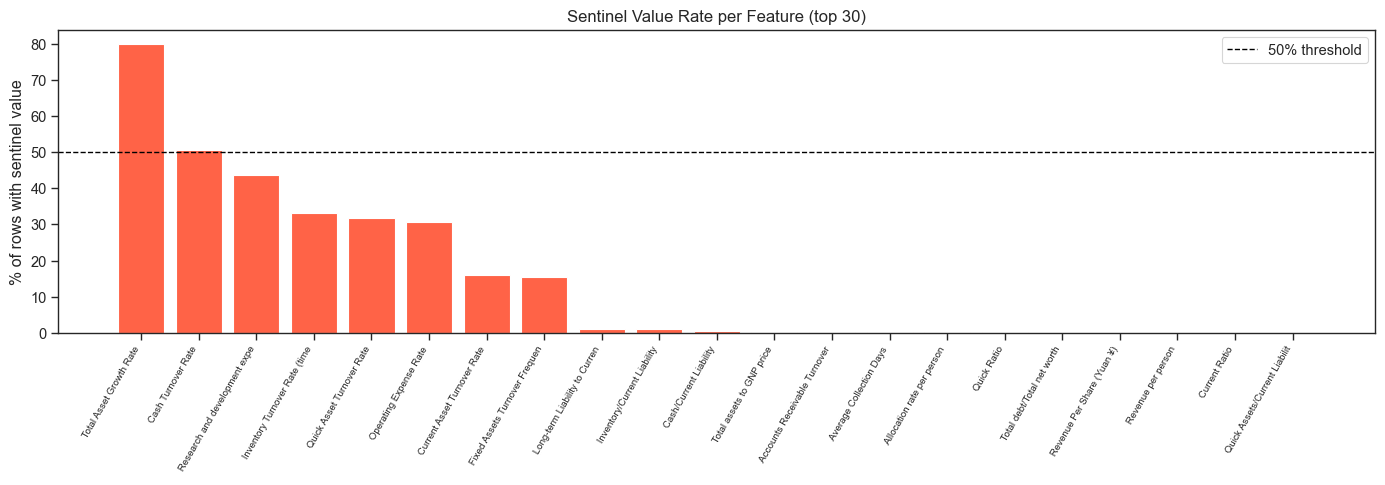

In [14]:
# Financial ratios should not exceed ~100x; values >= 1e9 are placeholder/sentinel
SENTINEL_THRESHOLD = 1e9
features_raw = [c for c in train_raw.columns if c != 'Bankrupt?']
num_features  = train_raw[features_raw].select_dtypes(include=[np.number]).columns.tolist()

# Count sentinel entries per column
sentinel_counts = {}
for col in num_features:
    n = (train_raw[col] >= SENTINEL_THRESHOLD).sum()
    if n > 0:
        sentinel_counts[col] = n

sentinel_series = pd.Series(sentinel_counts).sort_values(ascending=False)
sentinel_pct    = (sentinel_series / len(train_raw) * 100).round(2)

print(f"Columns with sentinel values (>= 1e9): {len(sentinel_series)} / {len(num_features)}")
print(f"\nTop 20 by sentinel count:")
summary = pd.DataFrame({'count': sentinel_series, 'pct(%)': sentinel_pct}).head(20)
print(summary.to_string())

# Compare raw mean vs median to expose scale distortion
print("\nScale distortion check — columns where mean >> 100× median:")
distorted = []
for col in num_features:
    med = train_raw[col].median()
    mean = train_raw[col].mean()
    if med != 0 and abs(mean / med) > 100:
        distorted.append((col, round(mean, 2), round(med, 6)))
    elif med == 0 and mean > 1e6:
        distorted.append((col, round(mean, 2), med))
dist_df = pd.DataFrame(distorted, columns=['Feature', 'Mean', 'Median']).sort_values('Mean', ascending=False)
print(dist_df.to_string(index=False))

# Bar chart of sentinel rates
fig, ax = plt.subplots(figsize=(14, 5))
top30 = sentinel_pct.head(30)
ax.bar(range(len(top30)), top30.values, color='tomato', edgecolor='white')
ax.set_xticks(range(len(top30)))
ax.set_xticklabels([c[:30] for c in top30.index], rotation=60, ha='right', fontsize=7)
ax.axhline(50, color='black', linestyle='--', linewidth=1, label='50% threshold')
ax.set_title('Sentinel Value Rate per Feature (top 30)', fontsize=12)
ax.set_ylabel('% of rows with sentinel value')
ax.legend()
plt.tight_layout()
plt.show()

---
### Key Observations
                                                                             
  1. **Turnover-based ratios dominate** — most sentinel-heavy features are   
  turnover rates. This is expected: companies with zero inventory, zero fixed      
  assets, or zero revenue produce undefined ratios.
                                                                             
  2. **Sentinel values are informative** — the *presence* of a sentinel      
  (i.e., the ratio being undefined) may itself signal financial distress. Consider   
  adding binary indicator columns (e.g., `has_inventory = 0/1`) before replacing with NaN.                                                                  
                                                                             
  ### Preprocessing Actions                                                  
                                                       

### Sentinel Value Analysis (values >= 1e9)

  21 out of 95 features contain sentinel values, which represent             
  undefined/impossible
  financial ratios (e.g., division by zero) encoded as large numbers rather  
  than NaN.                                                                  
  These must be replaced with NaN before imputation.
                                                                             
  #### Severity Tiers                                                         
                                                                             
  **Tier 1 — Critical (>30%): Drop or treat with extreme caution**           
  | Feature | Sentinel % | Reason likely undefined |
  |---|---|---|                                                              
  | Total Asset Growth Rate | 79.85% | No prior-year assets to compare |
  | Cash Turnover Rate | 50.58% | Zero or missing cash balance |             
  | Research and development expense rate | 43.76% | No R&D spend (common in 
  non-tech firms) |                                                          
  | Inventory Turnover Rate | 33.18% | Zero inventory (service companies) |  
  | Quick Asset Turnover Rate | 31.75% | Zero quick assets |                 
  | Operating Expense Rate | 30.61% | Zero or missing revenue |              
                                                                             
  → Total Asset Growth Rate (79.85%) **dropped**,
  → Others in this tier: retain but flag; after sentinel→NaN conversion,     
  missing rate                                                               
    will exceed 30%, so median imputation may introduce significant noise.
                                                                             
  **Tier 2 — Moderate (1–30%): Impute with median**                          
  | Feature | Sentinel % |                                                   
  |---|---|                                                                  
  | Current Asset Turnover Rate | 16.04% |
  | Fixed Assets Turnover Frequency | 15.60% |                               
  | Long-term Liability to Current Assets | 1.08% |
  | Inventory/Current Liability | 0.97% |                                    
  | Cash/Current Liability | 0.57% |
                                                                             
  → Safe to impute with training-set median after sentinel→NaN conversion.   
                                                                             
  **Tier 3 — Minor (<1%): Impute normally**                                  
  Remaining features (Total assets to GNP price, Accounts Receivable
  Turnover,                                                                  
  Average Collection Days, etc.) have <1% sentinel rate — negligible impact.
                                                                             
  



### Replace Sentinel Values with NaN

In [ ]:
SENTINEL_THRESHOLD = 1e9
train = train_raw.copy()
test  = test_raw.copy()


BINARY_COLS = ['Liability-Assets Flag', 'Net Income Flag'] # exclude binary flags and target
TARGET_COL  = 'Bankrupt?'

feat_cols = [c for c in train.columns
             if c not in BINARY_COLS + [TARGET_COL]]

# Replace sentinel values with NaN (train and test separately)
sentinel_mask_train = train[feat_cols] >= SENTINEL_THRESHOLD
sentinel_mask_test  = test[feat_cols]  >= SENTINEL_THRESHOLD
train[feat_cols] = train[feat_cols].where(~sentinel_mask_train, other=np.nan)
test[feat_cols]  = test[feat_cols].where(~sentinel_mask_test,  other=np.nan)

# Summary
n_replaced_train = sentinel_mask_train.sum().sum()
n_replaced_test  = sentinel_mask_test.sum().sum()
print(f"Sentinel values replaced → NaN")
print(f"  Train: {n_replaced_train:,} cells across {sentinel_mask_train.any().sum()} columns")
print(f"  Test:  {n_replaced_test:,} cells across {sentinel_mask_test.any().sum()} columns")

# Verify
assert (train[feat_cols] >= SENTINEL_THRESHOLD).sum().sum() == 0, "Sentinels remain in train!"
assert (test[feat_cols]  >= SENTINEL_THRESHOLD).sum().sum() == 0, "Sentinels remain in test!"
print("\nAssertion passed: no sentinel values remain.")

Sentinel values replaced → NaN
  Train: 16,647 cells across 21 columns
  Test:  4,151 cells across 21 columns

Assertion passed: no sentinel values remain.


---
## 1.3 Missing Value Analysis (post sentinel replacement)

Features with any missing values: 21 / 95

Columns exceeding 50% threshold (will be dropped):
                         missing_count  missing_pct
Total Asset Growth Rate           4356        79.85
Cash Turnover Rate                2759        50.58

All missing columns (sorted):
                                       missing_count  missing_pct
Total Asset Growth Rate                         4356        79.85
Cash Turnover Rate                              2759        50.58
Research and development expense rate           2387        43.76
Inventory Turnover Rate (times)                 1810        33.18
Quick Asset Turnover Rate                       1732        31.75
Operating Expense Rate                          1670        30.61
Current Asset Turnover Rate                      875        16.04
Fixed Assets Turnover Frequency                  851        15.60
Long-term Liability to Current Assets             59         1.08
Inventory/Current Liability                       53       

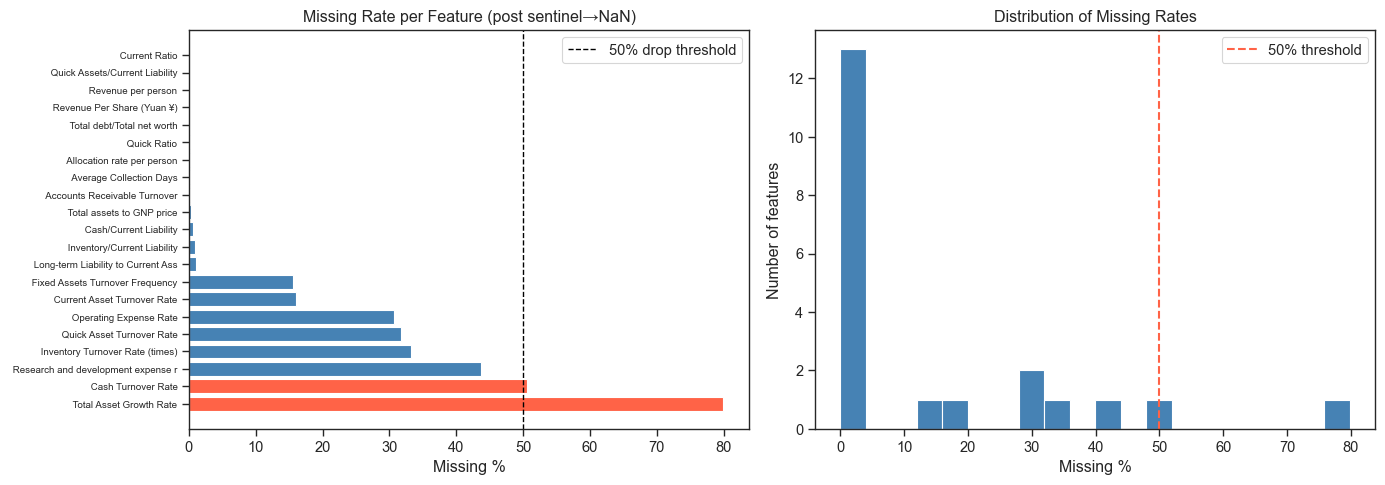


Decision: 2 column(s) to drop → [' Total Asset Growth Rate', ' Cash Turnover Rate']


In [19]:
DROP_THRESHOLD = 0.50  # drop columns with >50% missing

# --- Missing rate per column (train only) ---
missing_count = train[feat_cols].isnull().sum()
missing_pct   = missing_count / len(train) * 100

missing_df = pd.DataFrame({
    'missing_count': missing_count,
    'missing_pct':   missing_pct.round(2)
}).sort_values('missing_pct', ascending=False)

missing_df = missing_df[missing_df['missing_count'] > 0]

print(f"Features with any missing values: {len(missing_df)} / {len(feat_cols)}")
print(f"\nColumns exceeding {DROP_THRESHOLD*100:.0f}% threshold (will be dropped):")
drop_cols = missing_df[missing_df['missing_pct'] > DROP_THRESHOLD * 100].index.tolist()
print(missing_df[missing_df['missing_pct'] > DROP_THRESHOLD * 100].to_string())

print(f"\nAll missing columns (sorted):")
print(missing_df.to_string())

# --- Visualise missing rate ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: all columns with missing values
colors = ['tomato' if p > 50 else 'steelblue' for p in missing_df['missing_pct']]
axes[0].barh(range(len(missing_df)), missing_df['missing_pct'].values,
             color=colors, edgecolor='white')
axes[0].set_yticks(range(len(missing_df)))
axes[0].set_yticklabels([c[:35] for c in missing_df.index], fontsize=7)
axes[0].axvline(50, color='black', linestyle='--', linewidth=1, label='50% drop threshold')
axes[0].set_xlabel('Missing %')
axes[0].set_title('Missing Rate per Feature (post sentinel→NaN)')
axes[0].legend()

# Right: distribution of missing rates
axes[1].hist(missing_df['missing_pct'], bins=20, color='steelblue', edgecolor='white')
axes[1].axvline(50, color='tomato', linestyle='--', linewidth=1.5, label='50% threshold')
axes[1].set_xlabel('Missing %')
axes[1].set_ylabel('Number of features')
axes[1].set_title('Distribution of Missing Rates')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"\nDecision: {len(drop_cols)} column(s) to drop → {drop_cols}")


  ### Summary     
  ---
  After replacing sentinel values (>=1e9) with NaN: 21 out of 95 features have missing values                 
  
  ### Decision 1: Drop (>50% missing) — 2 columns                             
   
  | Feature | Missing % | Reason |                                            
  |---|---|---|   
  | Total Asset Growth Rate | 79.85% | Only 20% valid data; median imputation would fill 4,356 rows with same value — no signal |                         
  | Cash Turnover Rate | 50.58% | Borderline; just above threshold — drop for consistency |                                                               
  
  → **Drop both before any further processing.**                                                                                                                  
                  
  ### Decision 2: Impute with median — 19 columns                             
   
  Remaining 19 columns all have <50% missing. Use **training-set median** to  
  fill.           
                                                                              
  **High missing (30–44%) — imputation introduces noise, but retain for now:**
  | Feature | Missing % |
  |---|---|                                                                   
  | Research and development expense rate | 43.76% |
  | Inventory Turnover Rate (times) | 33.18% |                                
  | Quick Asset Turnover Rate | 31.75% |
  | Operating Expense Rate | 30.61% |                                         
                  
  → These features may still carry signal in their non-missing values.        
    Monitor feature importance after modeling — drop if consistently
  unimportant.                                                                
                  
  **Low missing (<20%) — safe to impute:**                                    
  All remaining 15 features have <16% missing rate.
  Median imputation introduces minimal distortion.                            
                                                                              
  ---                                                                                                                                                     


## 1.4 Correlation Analysis — Feature Importance Preview

Top 20 features by |correlation| with Bankrupt?:
Net Income to Total Assets                                -0.3286
ROA(A) before interest and % after tax                    -0.2892
ROA(B) before interest and depreciation after tax         -0.2785
ROA(C) before interest and depreciation before interest   -0.2658
Debt ratio %                                               0.2517
Net worth/Assets                                          -0.2517
Retained Earnings to Total Assets                         -0.2414
Persistent EPS in the Last Four Seasons                   -0.2343
Net profit before tax/Paid-in capital                     -0.2188
Per Share Net profit before tax (Yuan ¥)                  -0.2119
Current Liability to Assets                                0.1968
Working Capital to Total Assets                           -0.1966
Current Liability to Current Assets                        0.1843
Net Value Per Share (A)                                   -0.1826
Net Income to Stockholder's

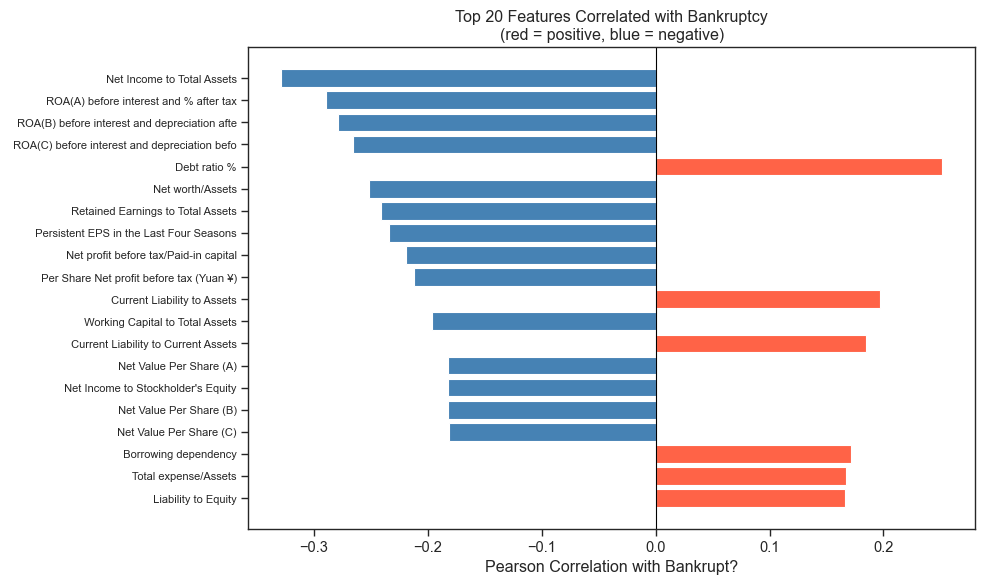

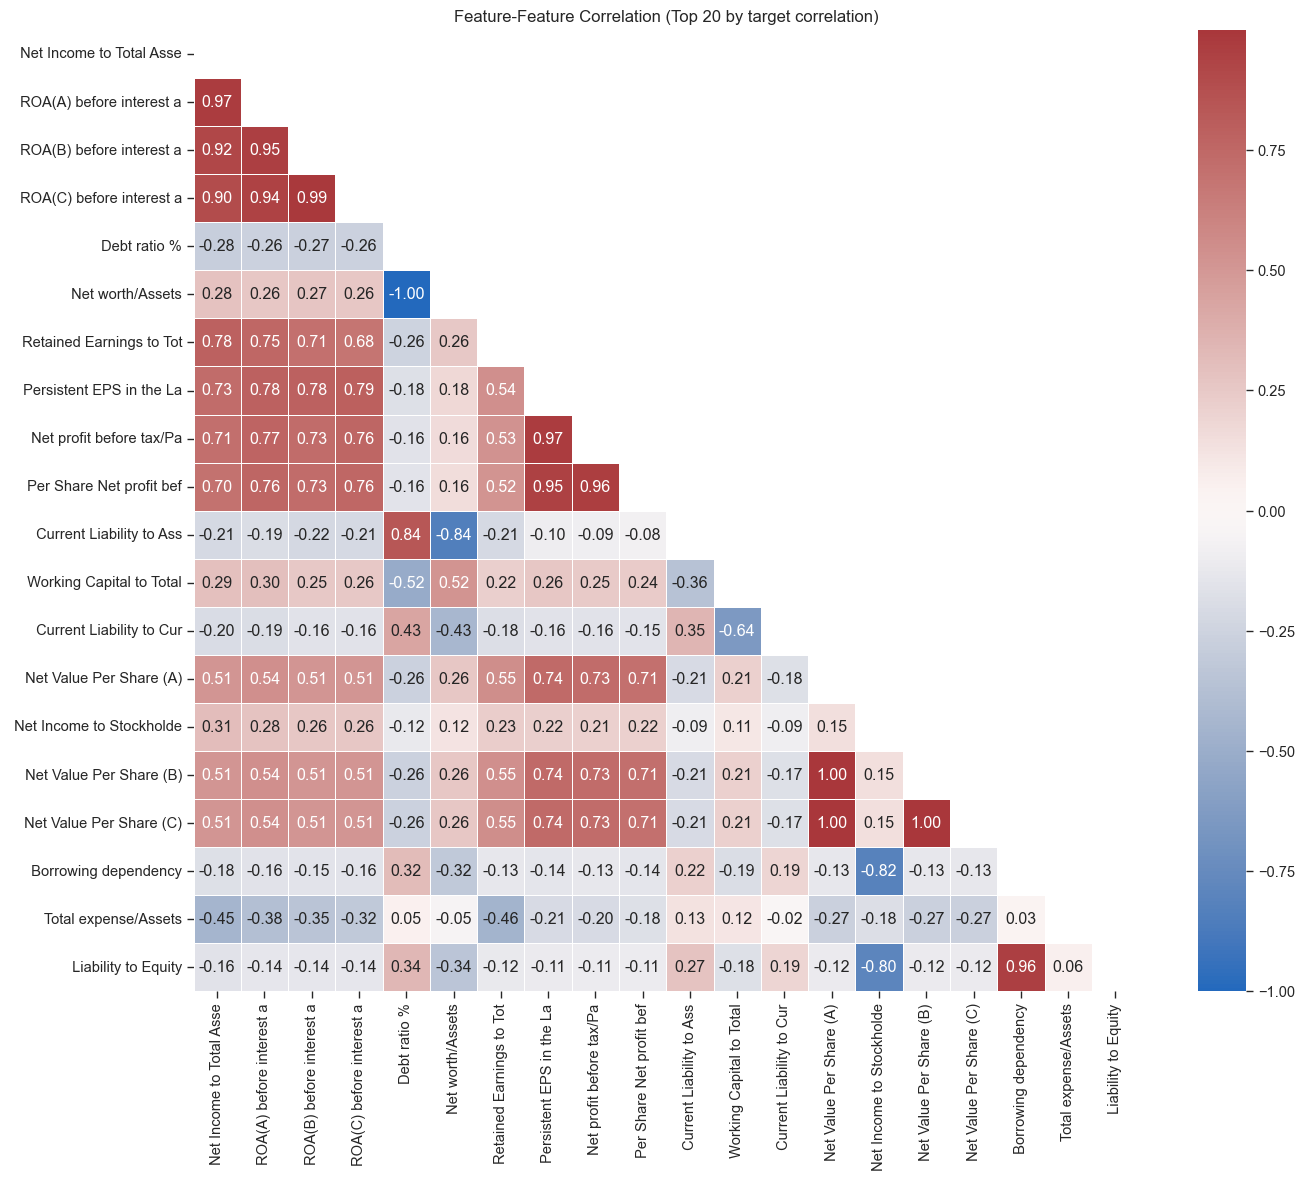


Highly collinear pairs (|r| > 0.90) among top 20:
  r=-1.000  |   Debt ratio %  ↔   Net worth/Assets
  r=+1.000  |   Net Value Per Share (A)  ↔   Net Value Per Share (C)
  r=+0.999  |   Net Value Per Share (A)  ↔   Net Value Per Share (B)
  r=+0.999  |   Net Value Per Share (B)  ↔   Net Value Per Share (C)
  r=+0.987  |   ROA(B) before interest and depreciation  ↔   ROA(C) before interest and depreciation
  r=+0.972  |   Net Income to Total Assets  ↔   ROA(A) before interest and % after tax
  r=+0.971  |   Persistent EPS in the Last Four Seasons  ↔   Net profit before tax/Paid-in capital
  r=+0.965  |   Net profit before tax/Paid-in capital  ↔   Per Share Net profit before tax (Yuan ¥
  r=+0.956  |   Borrowing dependency  ↔   Liability to Equity
  r=+0.954  |   ROA(A) before interest and % after tax  ↔   ROA(B) before interest and depreciation
  r=+0.945  |   Persistent EPS in the Last Four Seasons  ↔   Per Share Net profit before tax (Yuan ¥
  r=+0.939  |   ROA(A) before interest and

In [24]:
TARGET_COL = 'Bankrupt?'

# --- 3a. Pearson correlation with target ---
corr_target = (train[feat_cols + [TARGET_COL]]
               .corr()[TARGET_COL]
               .drop(TARGET_COL)
               .sort_values(key=abs, ascending=False))

top20_corr = corr_target.head(20)

print("Top 20 features by |correlation| with Bankrupt?:")
print(top20_corr.round(4).to_string())

# Bar chart
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['tomato' if v > 0 else 'steelblue' for v in top20_corr.values]
ax.barh(range(len(top20_corr)), top20_corr.values[::-1], color=colors[::-1], edgecolor='white')
ax.set_yticks(range(len(top20_corr)))
ax.set_yticklabels([c[:45] for c in top20_corr.index[::-1]], fontsize=8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Pearson Correlation with Bankrupt?')
ax.set_title('Top 20 Features Correlated with Bankruptcy\n(red = positive, blue = negative)')
plt.tight_layout()
plt.show()

# --- 3b. Feature-feature correlation heatmap (top 20) ---
top20_cols = top20_corr.index.tolist()

fig, ax = plt.subplots(figsize=(14, 12))
corr_matrix = train[top20_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # upper triangle mask
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='vlag',
            center=0, linewidths=0.5, ax=ax,
            xticklabels=[c[:25] for c in top20_cols],
            yticklabels=[c[:25] for c in top20_cols])
ax.set_title('Feature-Feature Correlation (Top 20 by target correlation)', fontsize=12)
plt.tight_layout()
plt.show()

# --- 3c. Flag highly collinear pairs ---
print("\nHighly collinear pairs (|r| > 0.90) among top 20:")
high_corr_pairs = []
for i in range(len(top20_cols)):
    for j in range(i+1, len(top20_cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.90:
            high_corr_pairs.append((top20_cols[i][:40], top20_cols[j][:40], round(r, 3)))

if high_corr_pairs:
    for a, b, r in sorted(high_corr_pairs, key=lambda x: abs(x[2]), reverse=True):
        print(f"  r={r:+.3f}  |  {a}  ↔  {b}")
else:
    print("  None found.")


  ### 1. Top Predictive Features                                              
   
  All top 20 features have |r| between 0.16–0.33, which is modest but         
  meaningful      
  for a heavily imbalanced dataset (3% event rate naturally suppresses        
  correlations).                                                              
   
  **Negative correlation (higher value → less likely bankrupt):**             
  - Net Income to Total Assets (-0.33) — strongest single predictor;
  profitable companies survive                                                
  - ROA variants (-0.27 to -0.29) — profitability protects against bankruptcy
  - Retained Earnings to Total Assets (-0.24) — accumulated profits as buffer 
  - Persistent EPS (-0.23) — sustained earnings signal stability              
  - Net Value Per Share A/B/C (-0.18) — equity value per share                
  - Working Capital to Total Assets (-0.20) — liquidity cushion               
                                                                              
  **Positive correlation (higher value → more likely bankrupt):**             
  - Debt ratio % (+0.25) — higher leverage → higher bankruptcy risk
  - Current Liability to Assets (+0.20) — short-term debt burden              
  - Current Liability to Current Assets (+0.18) — liquidity squeeze           
  - Borrowing dependency (+0.17), Liability to Equity (+0.17) — leverage      
  indicators                                                                  
                                                                              
  **Interpretation:** Bankruptcy is primarily driven by **low profitability + 
  high leverage**,
  consistent with classical financial distress theory (Altman Z-score         
  components).                                                                
   
  ---                                                                         
                  
  ### 2. High Collinearity — Redundant Feature Groups                         
                  
  Four distinct clusters of near-identical features identified:               
   
  **Group A — Perfect inverse pair (r = -1.000):**                            
  - `Debt ratio %` ↔ `Net worth/Assets`
  - Mathematically identical: Net worth/Assets = 1 - Debt ratio %             
  - **Action: drop `Net worth/Assets`, keep `Debt ratio %`**                  
                                                                              
  **Group B — Net Value Per Share variants (r > 0.999):**                     
  - `Net Value Per Share (A)` ↔ `(B)` ↔ `(C)` — effectively the same number   
  - **Action: keep only `Net Value Per Share (A)`, drop (B) and (C)**         
                                                                              
  **Group C — ROA variants (r = 0.939–0.987):**                               
  - ROA(A), ROA(B), ROA(C) — three slightly different depreciation/tax        
  adjustments                                                                 
  - All measure the same underlying concept (asset profitability)
  - **Action: keep `ROA(A) before interest and % after tax` (highest |r| with 
  target),                                                                    
    drop ROA(B) and ROA(C) — or let tree-based models handle it naturally**   
                                                                              
  **Group D — EPS / Per Share profit (r = 0.945–0.971):**                     
  - `Persistent EPS` ↔ `Net profit before tax/Paid-in capital` ↔ `Per Share   
  Net profit before tax`                                                      
  - **Action: keep `Persistent EPS in the Last Four Seasons` (highest |r| with
   target)**                                                                  
                  
  **Group E — Leverage pair (r = 0.956):**                                    
  - `Borrowing dependency` ↔ `Liability to Equity`
  - **Action: keep `Borrowing dependency` (slightly higher |r| with target)** 
                                                                              
  ---
                                                                              
  ### 3. Preprocessing Directions

  **Option A — for tree-based models:**            
  Drop only the perfect/near-perfect duplicates (r > 0.99).
  Tree models (Random Forest, XGBoost) handle collinearity naturally by       
  splitting importance across correlated features — removing them is not strictly necessary.
                  
  Drop: Net worth/Assets                                                      
  Drop: Net Value Per Share (B), Net Value Per Share (C)
  Keep everything else                                                        
                                                                              
  **Option B — for Logistic Regression, SVM:**
  
  Drop one from each collinear group (r > 0.90) to reduce multicollinearity.  
  Linear models are sensitive to correlated features and produce unstable     
  coefficients.                                                               
                                                                              
  Drop: Net worth/Assets                          (Group A)                   
  Drop: Net Value Per Share (B), (C)              (Group B)
  Drop: ROA(B), ROA(C)                            (Group C)                   
  Drop: Net profit before tax/Paid-in capital,    (Group D)
        Per Share Net profit before tax                                       
  Drop: Liability to Equity                       (Group E)
                                                                              
  **Decision rule:**
  - Using Random Forest / XGBoost → Option A                                  
  - Using Logistic Regression / SVM → Option B                                
  - Final modeling stage: let feature importance scores confirm which to keep 
                                      

## 1.5 Feature Distribution — Bankrupt vs Non-Bankrupt

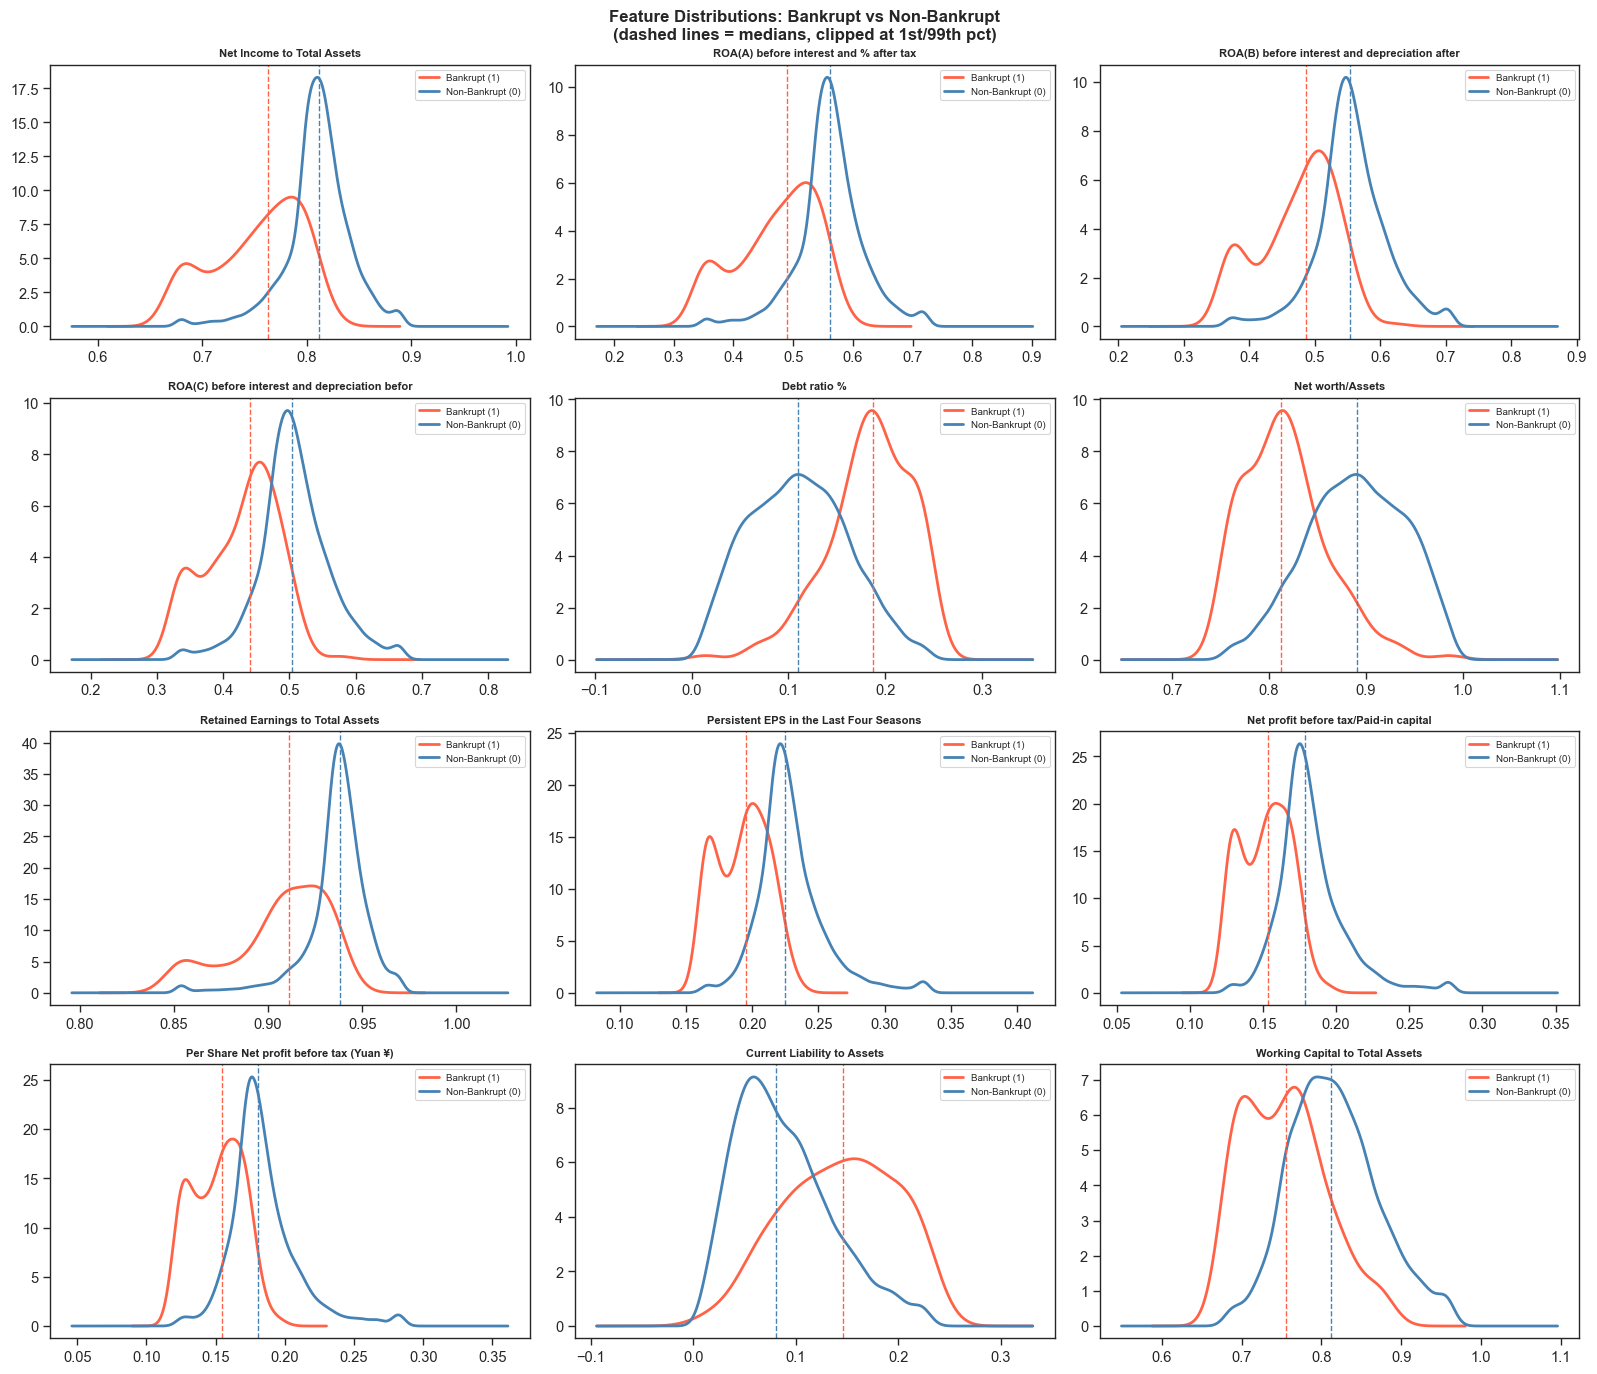

Median values by class:
Feature                                                   Non-Bankrupt   Bankrupt  Ratio (B/NB)
-----------------------------------------------------------------------------------------------
Net Income to Total Assets                                      0.8115     0.7627          0.94x
ROA(A) before interest and % after tax                          0.5612     0.4892          0.87x
ROA(B) before interest and depreciation after tax               0.5536     0.4874          0.88x
ROA(C) before interest and depreciation before interest         0.5045     0.4404          0.87x
Debt ratio %                                                    0.1096     0.1874          1.71x
Net worth/Assets                                                0.8904     0.8126          0.91x
Retained Earnings to Total Assets                               0.9381     0.9109          0.97x
Persistent EPS in the Last Four Seasons                         0.2251     0.1953          0.87x
Net prof

In [ ]:
plot_features = corr_target.head(12).index.tolist()

bankrupt     = train[train[TARGET_COL] == 1]
non_bankrupt = train[train[TARGET_COL] == 0]

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()

for i, feat in enumerate(plot_features):
    ax = axes[i]

    # Clip extreme values at 1st/99th percentile for readability
    lo = train[feat].quantile(0.01)
    hi = train[feat].quantile(0.99)
    b_vals  = bankrupt[feat].clip(lo, hi).dropna()
    nb_vals = non_bankrupt[feat].clip(lo, hi).dropna()

    # KDE plots
    b_vals.plot.kde(ax=ax, color='tomato',    label='Bankrupt (1)',     linewidth=2)
    nb_vals.plot.kde(ax=ax, color='steelblue', label='Non-Bankrupt (0)', linewidth=2)

    # Vertical medians
    ax.axvline(b_vals.median(),  color='tomato',    linestyle='--', linewidth=1)
    ax.axvline(nb_vals.median(), color='steelblue', linestyle='--', linewidth=1)

    ax.set_title(feat.strip()[:45], fontsize=8, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.legend(fontsize=7)

plt.suptitle('Feature Distributions: Bankrupt vs Non-Bankrupt\n(dashed lines = medians, clipped at 1st/99th pct)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Median comparison table ---
print("Median values by class:")
print(f"{'Feature':<55} {'Non-Bankrupt':>14} {'Bankrupt':>10} {'Ratio (B/NB)':>13}")
print("-" * 95)
for feat in plot_features:
    nb_med = non_bankrupt[feat].median()
    b_med  = bankrupt[feat].median()
    ratio  = b_med / nb_med if nb_med != 0 else float('nan')
    print(f"{feat.strip():<55} {nb_med:>14.4f} {b_med:>10.4f} {ratio:>13.2f}x")

  ### 1. Profitability Features (Negative correlation — lower in bankrupt firms)
  | Feature | Non-Bankrupt | Bankrupt | Ratio |
  |---|---|---|---|
  | Net Income to Total Assets | 0.8115 | 0.7627 | 0.94x |
  | ROA(A) | 0.5612 | 0.4892 | 0.87x |                                        
  | ROA(B) | 0.5536 | 0.4874 | 0.88x |
  | ROA(C) | 0.5045 | 0.4404 | 0.87x |                                        
  | Retained Earnings to Total Assets | 0.9381 | 0.9109 | 0.97x |             
  | Persistent EPS | 0.2251 | 0.1953 | 0.87x |                                
  | Net profit before tax/Paid-in capital | 0.1790 | 0.1535 | 0.86x |         
  | Per Share Net profit before tax | 0.1803 | 0.1545 | 0.86x |
                                                              
  **Observation:** All profitability metrics are lower in bankrupt firms, but 
  the median differences are modest (~6–13%). This means these features alone cannot cleanly separate the two classes — the KDE distributions will overlap significantly. The model needs to combine multiple features to detect bankruptcy.          
                  
  **Note on Retained Earnings (ratio=0.97x):** Almost identical medians suggest this feature has limited marginal value beyond what ROA already captures.        
                                                                              
  ---
                                                                              
  ### 2. Leverage Features (Positive correlation — higher in bankrupt firms)

  | Feature | Non-Bankrupt | Bankrupt | Ratio |
  |---|---|---|---|
  | Debt ratio % | 0.1096 | 0.1874 | **1.71x** |                              
  | Current Liability to Assets | 0.0805 | 0.1463 | **1.82x** |               
  | Net worth/Assets | 0.8904 | 0.8126 | 0.91x |                              
                                                                              
  **Observation:** Leverage features show the strongest separation — bankrupt 
  firms carry ~1.7–1.8x more debt relative to assets. `Debt ratio %` and            
  `Current Liability to Assets` are the most discriminative features in this  
  dataset.                                                                    
                                                                              
  **Note:** `Net worth/Assets` is the mirror of `Debt ratio %` (they sum to   
  ~1.0), confirming the earlier finding that one should be dropped.                  
                                                                              
  ---
                                                                              
  ### 3. Liquidity Features

  | Feature | Non-Bankrupt | Bankrupt | Ratio |                               
  |---|---|---|---|
  | Working Capital to Total Assets | 0.8117 | 0.7555 | 0.93x |               
                  
  **Observation:** Modest difference (7%). Working capital provides some      
  signal but is less discriminative than the leverage features.                      
                                                                              
  ---
                                                                              
  ### Key Takeaways for Modeling                                              
   
  1. **No single feature cleanly separates the classes** — all median ratios  
  are close to 1.0. This is expected for financial distress prediction and is  
  why ensemble methods (Random Forest, XGBoost) outperform single-feature
  rules.                                                                      
                  
  2. **Leverage > Profitability** in terms of separation power — `Debt ratio  
  %`and `Current Liability to Assets` show the largest median gaps (1.7–1.8x).                                                                 
   
  3. **Heavy overlap expected in KDE plots** — bankrupt companies'            
  distributions sit mostly within the non-bankrupt distribution, shifted slightly. This makes threshold selection critical (see imbalance handling notes).  
                                                                              
  4. **ROA variants are near-identical** — ROA(A), (B), (C) have almost the   
  same median ratios (0.87–0.88x). Keep only ROA(A) as confirmed in correlation analysis.                                                                

## 1.6 Binary Flag Columns Analysis

Binary flag columns found: [' Liability-Assets Flag', ' Net Income Flag']


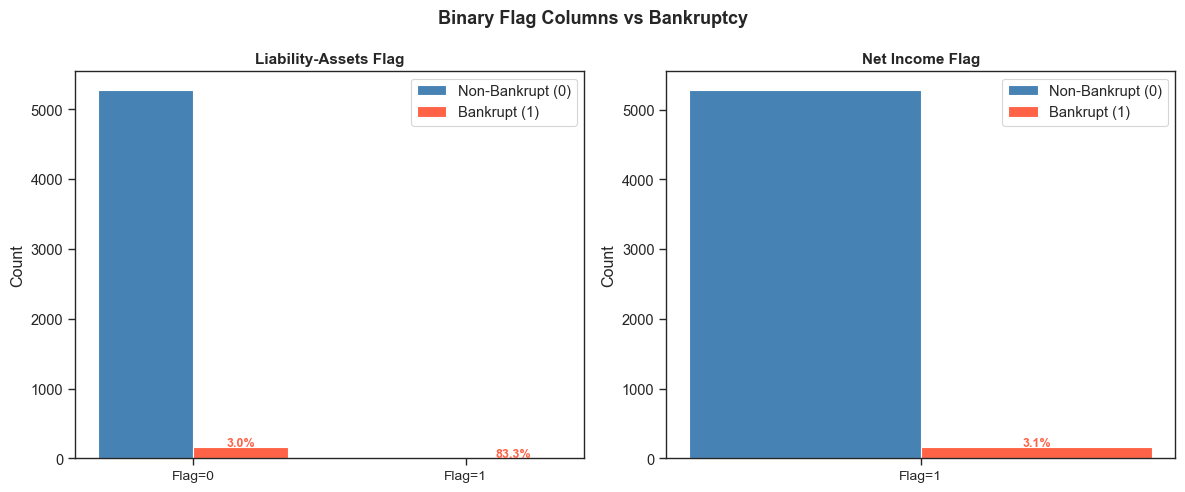

Liability-Assets Flag
  Value counts: {0: 5449, 1: 6}
  Bankruptcy rate by flag value:
    Flag=0: 165/5449 bankrupt (3.03%)
    Flag=1: 5/6 bankrupt (83.33%)
  Pearson r with Bankrupt?: 0.1532
Net Income Flag
  Value counts: {1: 5455}
  Bankruptcy rate by flag value:
    Flag=1: 170/5455 bankrupt (3.12%)
  Pearson r with Bankrupt?: nan


In [32]:
BINARY_COLS = [c for c in train.columns if 'Flag' in c]
print(f"Binary flag columns found: {BINARY_COLS}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, col in enumerate(BINARY_COLS):
    ax = axes[i]

    ct     = pd.crosstab(train[col], train[TARGET_COL])
    ct_pct = pd.crosstab(train[col], train[TARGET_COL], normalize='index') * 100

    x = np.arange(len(ct.index))
    width = 0.35
    ax.bar(x - width/2, ct[0], width, label='Non-Bankrupt (0)', color='steelblue', edgecolor='white')
    ax.bar(x + width/2, ct[1], width, label='Bankrupt (1)',     color='tomato',    edgecolor='white')

    ax.set_xticks(x)
    ax.set_xticklabels([f'Flag={v}' for v in ct.index], fontsize=10)
    ax.set_title(col.strip(), fontsize=11, fontweight='bold')
    ax.set_ylabel('Count')
    ax.legend()

    for j, flag_val in enumerate(ct.index):
        rate = ct_pct.loc[flag_val, 1]
        ax.text(j + width/2, ct.loc[flag_val, 1] + 10,
                f'{rate:.1f}%', ha='center', fontsize=9, color='tomato', fontweight='bold')

plt.suptitle('Binary Flag Columns vs Bankruptcy', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Detailed stats ---
print("=" * 60)
for col in BINARY_COLS:
    ct     = pd.crosstab(train[col], train[TARGET_COL])
    ct_pct = pd.crosstab(train[col], train[TARGET_COL], normalize='index') * 100
    print(f"{col.strip()}")
    print(f"  Value counts: {train[col].value_counts().to_dict()}")
    print(f"  Bankruptcy rate by flag value:")
    for flag_val in ct.index:
        total      = ct.loc[flag_val].sum()
        bankrupt_n = ct.loc[flag_val, 1]
        rate       = ct_pct.loc[flag_val, 1]
        print(f"    Flag={flag_val}: {bankrupt_n}/{total} bankrupt ({rate:.2f}%)")
    r = train[col].corr(train[TARGET_COL])
    print(f"  Pearson r with Bankrupt?: {r:.4f}")
print("=" * 60)

### Binary Flag Columns — Conclusions                                        
                                                              
  **Liability-Assets Flag**                                                   
  - Only 6 samples have Flag=1 (liabilities > assets), but 5 of them are      
  bankrupt (83.3% vs 3% baseline).                                            
  - Signal is extremely strong but statistically fragile due to near-zero
  frequency.                                                                  
  - Decision: **retain** — tree-based models will exploit this edge case
  effectively.                                                                
                  
  **Net Income Flag**                                                         
  - All 5,455 training samples have Flag=1. Zero variance, correlation = NaN.
  - Carries no predictive information whatsoever.                             
  - Decision: **drop** before modeling.    

# 2. Feature Engineering & Preprocessing

## 2.1 Drop Columns

In [35]:
# ── DROP_ALL: remove for ALL models ───────────────────────────────────────────
# Reason: >50% missing, zero variance, or r=1.000 perfect duplicates
DROP_ALL_KW = [
    # High missing rate
    'Total Asset Growth Rate',
    'Cash Turnover Rate',
    # Zero variance
    'Net Income Flag',
    # Perfect duplicates of Debt ratio %
    'Net worth/Assets',
    # Perfect duplicates of Net Value Per Share (A)
    'Net Value Per Share (B)',
    'Net Value Per Share (C)',
    # Three-way r=1.000 group → keep Gross Profit to Sales (directly named)
    'Operating Gross Margin',
    'Realized Sales Gross Margin',
    # r=1.000 naming duplicates
    'Current Liabilities/Liability',   # duplicate of Current Liability to Liability
    'Current Liabilities/Equity',      # duplicate of Current Liability to Equity
]

# ── DROP_LINEAR_EXTRA: additional drops for LR / SVM only ─────────────────────
# Reason: r > 0.90 collinearity — tree models handle these natively
DROP_LINEAR_KW = [
    # ROA variants (keep ROA(A))
    'ROA(B)',
    'ROA(C)',
    # EPS / per-share profit group (keep Persistent EPS)
    'Net profit before tax/Paid-in capital',
    'Per Share Net profit before tax',
    # Leverage group (keep Borrowing dependency)
    'Liability to Equity',
    # Operating profit per share vs paid-in capital (keep Operating profit/Paid-in capital)
    'Operating Profit Per Share',
    # Quick ratio duplicate (keep Quick Ratio — more standard name)
    'Quick Assets/Current Liability',
    # Growth rate group (keep After-tax Net Profit Growth Rate)
    'Regular Net Profit Growth Rate',
    # Interest rate group (keep Pre-tax net Interest Rate)
    'After-tax net Interest Rate',
]

def drop(df, linear=False):
    """
    Drop redundant and uninformative columns identified in EDA + collinearity sweep.
    linear=True: also drop high-collinearity features for LR/SVM models.
    Returns a copy — original df is not modified.
    """
    df = df.copy()
    kws = DROP_ALL_KW + (DROP_LINEAR_KW if linear else [])
    cols_to_drop = [c for c in df.columns if any(kw in c for kw in kws)]
    return df.drop(columns=cols_to_drop)

# ── Verify ─────────────────────────────────────────────────────────────────────
train_dropped = drop(train, linear=False)
test_dropped  = drop(test,  linear=False)

n_all    = len([c for c in train.columns if any(kw in c for kw in DROP_ALL_KW)])
n_linear = len([c for c in train.columns if any(kw in c for kw in DROP_LINEAR_KW)])
print(f"DROP_ALL:          {n_all} cols  →  {train_dropped.shape[1]-1} features remain")
print(f"DROP_LINEAR_EXTRA: {n_linear} cols  →  {train_dropped.shape[1]-1-n_linear} features remain (linear models)")
print(f"\nTrain shape: {train_dropped.shape}  |  Test shape: {test_dropped.shape}")

DROP_ALL:          10 cols  →  85 features remain
DROP_LINEAR_EXTRA: 10 cols  →  75 features remain (linear models)

Train shape: (5455, 86)  |  Test shape: (1364, 85)


## 2.2 Median Imputation

In [40]:
from sklearn.impute import SimpleImputer

MISSING_FLAG_THRESHOLD = 0.05   # add indicator for features with >5% missing
FLAG_SIGNAL_THRESHOLD  = 1.20   # keep flag only if bankrupt rate ratio > 1.20x

def impute(train_df, test_df, target_col='Bankrupt?'):
    """
    Median imputation with missingness indicators.
    1. Add binary flag for columns with >5% missing
    2. Drop flags where missing/present bankruptcy rate ratio <= 1.25 (no signal)
    3. Fill all NaN with training-set median
    Returns (train_imputed, test_imputed, imputer, flag_cols_kept).
    """
    train_df = train_df.copy()
    test_df  = test_df.copy()

    feat_cols = [c for c in train_df.columns if c != target_col]

    # Step 1: add missingness indicators for high-missing columns
    missing_rate = train_df[feat_cols].isnull().mean()
    high_missing = missing_rate[missing_rate > MISSING_FLAG_THRESHOLD].index.tolist()

    flag_cols_all = []
    for col in high_missing:
        flag_name = col.strip() + '_missing'
        train_df[flag_name] = train_df[col].isnull().astype(int)
        test_df[flag_name]  = test_df[col].isnull().astype(int)
        flag_cols_all.append(flag_name)

    # Step 2: filter — keep flags only if bankruptcy rate ratio > threshold
    flag_cols_kept = []
    flag_cols_dropped = []
    for c in flag_cols_all:
        rate_missing = train_df.loc[train_df[c] == 1, target_col].mean()
        rate_present = train_df.loc[train_df[c] == 0, target_col].mean()
        ratio = rate_missing / rate_present if rate_present > 0 else 0

        if ratio > FLAG_SIGNAL_THRESHOLD:
            flag_cols_kept.append(c)
        else:
            flag_cols_dropped.append(c)
            train_df.drop(columns=c, inplace=True)
            test_df.drop(columns=c, inplace=True)

    # Step 3: median imputation (exclude target and kept flags)
    feat_cols_impute = [c for c in train_df.columns
                        if c != target_col and c not in flag_cols_kept]

    imputer = SimpleImputer(strategy='median')
    train_df[feat_cols_impute] = imputer.fit_transform(train_df[feat_cols_impute])
    test_df[feat_cols_impute]  = imputer.transform(test_df[feat_cols_impute])

    return train_df, test_df, imputer, flag_cols_kept

# Apply
train_imputed, test_imputed, imputer, flag_cols = impute(train_dropped, test_dropped)

# Verify
train_nulls = train_imputed.isnull().sum().sum()
test_nulls  = test_imputed.isnull().sum().sum()
print(f"Remaining NaNs — train: {train_nulls}  |  test: {test_nulls}")
assert train_nulls == 0 and test_nulls == 0, "NaN values remain!"
print("Assertion passed: all missing values filled.")

print(f"\nMissingness flags kept (ratio > {FLAG_SIGNAL_THRESHOLD}):")
for c in flag_cols:
    rate_m = train_imputed.loc[train_imputed[c] == 1, TARGET_COL].mean() * 100
    rate_p = train_imputed.loc[train_imputed[c] == 0, TARGET_COL].mean() * 100
    ratio  = rate_m / rate_p if rate_p > 0 else 0
    print(f"  {c:<45} ratio={ratio:.2f}x  (missing={rate_m:.2f}%, present={rate_p:.2f}%)")

print(f"\nFinal shape — train: {train_imputed.shape}  |  test: {test_imputed.shape}")

Remaining NaNs — train: 0  |  test: 0
Assertion passed: all missing values filled.

Missingness flags kept (ratio > 1.2):
  Inventory Turnover Rate (times)_missing       ratio=1.22x  (missing=3.54%, present=2.91%)
  Fixed Assets Turnover Frequency_missing       ratio=2.25x  (missing=5.88%, present=2.61%)
  Current Asset Turnover Rate_missing           ratio=1.21x  (missing=3.66%, present=3.01%)
  Quick Asset Turnover Rate_missing             ratio=1.50x  (missing=4.04%, present=2.69%)

Final shape — train: (5455, 90)  |  test: (1364, 89)


## 2.3 Feature Scaling

In [41]:
from sklearn.preprocessing import StandardScaler

def scale(train_df, test_df, target_col='Bankrupt?'):
    """
    StandardScaler — fit on train only, transform both.
    Binary columns (0/1 flags) are excluded from scaling.
    Required for LR/SVM; optional for tree-based models.
    Returns (train_scaled, test_scaled, scaler).
    """
    train_df = train_df.copy()
    test_df  = test_df.copy()

    # Identify binary columns (0/1 only) — don't scale these
    binary_cols = [c for c in train_df.columns
                   if c != target_col and train_df[c].dropna().isin([0, 1]).all()]

    # Continuous columns to scale
    scale_cols = [c for c in train_df.columns
                  if c != target_col and c not in binary_cols]

    scaler = StandardScaler()
    train_df[scale_cols] = scaler.fit_transform(train_df[scale_cols])
    test_df[scale_cols]  = scaler.transform(test_df[scale_cols])

    return train_df, test_df, scaler

# Apply
train_scaled, test_scaled, scaler = scale(train_imputed, test_imputed)

# Verify: scaled continuous features should have mean ≈ 0, std ≈ 1
feat_cols_check = [c for c in train_scaled.columns
                   if c != TARGET_COL and not train_scaled[c].isin([0,1]).all()]
means = train_scaled[feat_cols_check].mean()
stds  = train_scaled[feat_cols_check].std()

print(f"Scaled {len(feat_cols_check)} continuous features (excluded binary flags)")
print(f"  Mean range: [{means.min():.6f}, {means.max():.6f}]  (should be ≈ 0)")
print(f"  Std  range: [{stds.min():.6f}, {stds.max():.6f}]  (should be ≈ 1)")
print(f"\nFinal shape — train: {train_scaled.shape}  |  test: {test_scaled.shape}")

Scaled 84 continuous features (excluded binary flags)
  Mean range: [-0.000000, 0.000000]  (should be ≈ 0)
  Std  range: [1.000092, 1.000092]  (should be ≈ 1)

Final shape — train: (5455, 90)  |  test: (1364, 89)


## 2.4 Combined Preprocessing Function

In [43]:
def preprocess(train_raw, test_raw, target_col='Bankrupt?',
               linear=False, do_scale=True):
    """
    Full preprocessing pipeline:
      1. Sentinel values (>= 1e9) → NaN
      2. Drop redundant / uninformative columns
      3. Median imputation + missingness indicators (signal ratio > 1.25)
      4. Feature scaling (optional, for LR/SVM)

    Parameters
    ----------
    train_raw : DataFrame with target column
    test_raw  : DataFrame without target column
    linear    : if True, drop extra collinear features for linear models
    do_scale  : if True, apply StandardScaler to continuous features

    Returns
    -------
    X_train, X_test, y_train, artifacts
        artifacts = dict with imputer, scaler, flag_cols for reproducibility
    """
    train = train_raw.copy()
    test  = test_raw.copy()

    # ── Step 1: Sentinel → NaN ──────────────────────────────────────────────
    SENTINEL_THRESHOLD = 1e9
    binary_flag_cols = [c for c in train.columns if 'Flag' in c]
    feat_cols = [c for c in train.columns
                 if c not in binary_flag_cols + [target_col]]

    train[feat_cols] = train[feat_cols].where(train[feat_cols] < SENTINEL_THRESHOLD, np.nan)
    test[feat_cols]  = test[feat_cols].where(test[feat_cols] < SENTINEL_THRESHOLD, np.nan)

    # ── Step 2: Drop columns ────────────────────────────────────────────────
    train = drop(train, linear=linear)
    test  = drop(test,  linear=linear)

    # ── Step 3: Impute ──────────────────────────────────────────────────────
    train, test, imp, flag_cols_kept = impute(train, test, target_col=target_col)

    # ── Step 4: Scale (optional) ────────────────────────────────────────────
    scl = None
    if do_scale:
        train, test, scl = scale(train, test, target_col=target_col)

    # ── Separate X and y ────────────────────────────────────────────────────
    y_train = train[target_col]
    X_train = train.drop(columns=target_col)
    X_test  = test

    artifacts = {
        'imputer':   imp,
        'scaler':    scl,
        'flag_cols': flag_cols_kept,
    }

    return X_train, X_test, y_train, artifacts


In [44]:
# For tree-based models (no scaling)
X_train, X_test, y_train, artifacts = preprocess(train_raw, test_raw, linear=False, do_scale=False)
print("=== Tree-model preprocessing ===")
print(f"  X_train: {X_train.shape}  |  X_test: {X_test.shape}  |  y_train: {y_train.shape}")
print(f"  NaN remaining: {X_train.isnull().sum().sum() + X_test.isnull().sum().sum()}")
print(f"  Flag cols kept: {artifacts['flag_cols']}")

# For linear models (with scaling)
X_train_lr, X_test_lr, y_train_lr, artifacts_lr = preprocess(train_raw, test_raw, linear=True, do_scale=True)
print("\n=== Linear-model preprocessing ===")
print(f"  X_train: {X_train_lr.shape}  |  X_test: {X_test_lr.shape}  |  y_train: {y_train_lr.shape}")
print(f"  NaN remaining: {X_train_lr.isnull().sum().sum() + X_test_lr.isnull().sum().sum()}")
print(f"  Flag cols kept: {artifacts_lr['flag_cols']}")

=== Tree-model preprocessing ===
  X_train: (5455, 89)  |  X_test: (1364, 89)  |  y_train: (5455,)
  NaN remaining: 0
  Flag cols kept: ['Inventory Turnover Rate (times)_missing', 'Fixed Assets Turnover Frequency_missing', 'Current Asset Turnover Rate_missing', 'Quick Asset Turnover Rate_missing']

=== Linear-model preprocessing ===
  X_train: (5455, 79)  |  X_test: (1364, 79)  |  y_train: (5455,)
  NaN remaining: 0
  Flag cols kept: ['Inventory Turnover Rate (times)_missing', 'Fixed Assets Turnover Frequency_missing', 'Current Asset Turnover Rate_missing', 'Quick Asset Turnover Rate_missing']


# 3. Modeling

## 3.1 Train / Validation Split

In [45]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import f1_score, classification_report, roc_auc_score

# ── Hold-out split: 80% train / 20% validation ─────────────────────────────
# Stratified to preserve ~3% bankruptcy rate in both sets
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# ── Cross-validation strategy ──────────────────────────────────────────────
# Used later for model tuning — defined here once for consistency
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ── Verify class distribution ──────────────────────────────────────────────
print("Class distribution check:")
print(f"  Full train:   {y_train.value_counts().to_dict()}  ({y_train.mean()*100:.2f}% bankrupt)")
print(f"  Train split:  {y_tr.value_counts().to_dict()}  ({y_tr.mean()*100:.2f}% bankrupt)")
print(f"  Val split:    {y_val.value_counts().to_dict()}  ({y_val.mean()*100:.2f}% bankrupt)")
print(f"\n  X_tr:  {X_tr.shape}  |  X_val: {X_val.shape}")

Class distribution check:
  Full train:   {0: 5285, 1: 170}  (3.12% bankrupt)
  Train split:  {0: 4228, 1: 136}  (3.12% bankrupt)
  Val split:    {0: 1057, 1: 34}  (3.12% bankrupt)

  X_tr:  (4364, 89)  |  X_val: (1091, 89)


## 3.2 Baseline — Random Forest

In [56]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import precision_recall_curve

def evaluate_model(model, X_tr, y_tr, X_val, y_val, cv, model_name='Model'):
    """
    Full evaluation pipeline for any classifier:
      1. CV scores (F1 + AUC-ROC) on X_tr
      2. Fit on X_tr, predict probabilities on X_val
      3. Find optimal threshold maximising F1
      4. Print comparison table + classification report
      5. Plot threshold vs F1 curve
    
    Returns dict with model, threshold, val_f1, cv_f1, cv_auc, y_val_proba.
    """
    # ── 1. CV evaluation ────────────────────────────────────────────────────
    cv_f1  = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='f1')
    cv_auc = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='roc_auc')

    print(f"=== {model_name} (CV on X_tr) ===")
    print(f"  F1:      {cv_f1.mean():.4f} ± {cv_f1.std():.4f}  {cv_f1.round(4)}")
    print(f"  AUC-ROC: {cv_auc.mean():.4f} ± {cv_auc.std():.4f}  {cv_auc.round(4)}")

    # ── 2. Fit + predict probabilities ──────────────────────────────────────
    model.fit(X_tr, y_tr)
    y_val_proba = model.predict_proba(X_val)[:, 1]

    # ── 3. Optimal threshold ───────────────────────────────────────────────
    precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_proba)
    f1_arr = 2 * precisions * recalls / (precisions + recalls + 1e-8)
    best_idx = f1_arr[:-1].argmax()
    best_threshold = thresholds[best_idx]
    best_f1 = f1_arr[best_idx]

    # Compare with default 0.5
    f1_default = f1_score(y_val, (y_val_proba >= 0.5).astype(int))
    y_val_pred = (y_val_proba >= best_threshold).astype(int)

    print(f"\n=== Threshold Tuning (X_val) ===")
    print(f"  Default (0.5):     F1 = {f1_default:.4f}")
    print(f"  Optimised ({best_threshold:.4f}): F1 = {best_f1:.4f}")

    # ── 4. Classification report ────────────────────────────────────────────
    print(f"\n=== Classification Report (optimised threshold) ===")
    print(classification_report(y_val, y_val_pred,
                                target_names=['Non-Bankrupt', 'Bankrupt']))

    # ── 5. Plot ─────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(thresholds, f1_arr[:-1], color='steelblue', linewidth=2)
    ax.axvline(best_threshold, color='tomato', linestyle='--',
               label=f'Best = {best_threshold:.4f}')
    ax.axvline(0.5, color='gray', linestyle=':', label='Default = 0.5')
    ax.set_xlabel('Threshold')
    ax.set_ylabel('F1 Score')
    ax.set_title(f'F1 vs Probability Threshold ({model_name})')
    ax.legend()
    plt.tight_layout()
    plt.show()

    return {
        'model':        model,
        'model_name':   model_name,
        'threshold':    best_threshold,
        'val_f1':       best_f1,
        'cv_f1_mean':   cv_f1.mean(),
        'cv_f1_std':    cv_f1.std(),
        'cv_auc_mean':  cv_auc.mean(),
        'y_val_proba':  y_val_proba,
    }

print("evaluate_model() defined.")

evaluate_model() defined.


=== Random Forest (CV on X_tr) ===
  F1:      0.2559 ± 0.1097  [0.2353 0.4    0.2941 0.0645 0.2857]
  AUC-ROC: 0.9487 ± 0.0114  [0.9514 0.9388 0.9676 0.9351 0.9505]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.1633
  Optimised (0.2467): F1 = 0.4167

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.98      0.98      1057
    Bankrupt       0.39      0.44      0.42        34

    accuracy                           0.96      1091
   macro avg       0.69      0.71      0.70      1091
weighted avg       0.96      0.96      0.96      1091



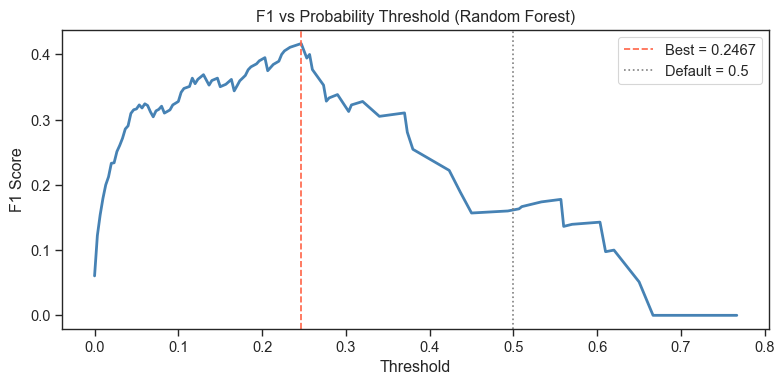

In [57]:
rf_result = evaluate_model(
    RandomForestClassifier(n_estimators=300, class_weight='balanced',random_state=42, n_jobs=-1),
    X_tr, y_tr, X_val, y_val, cv, model_name='Random Forest'
  )

=== Random Forest (CV on X_tr) ===
  F1:      0.2479 ± 0.1082  [0.2286 0.4    0.2941 0.0667 0.25  ]
  AUC-ROC: 0.9432 ± 0.0134  [0.9436 0.9218 0.9641 0.9417 0.9448]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.1702
  Optimised (0.2600): F1 = 0.4058

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.98      0.98      1057
    Bankrupt       0.40      0.41      0.41        34

    accuracy                           0.96      1091
   macro avg       0.69      0.70      0.69      1091
weighted avg       0.96      0.96      0.96      1091



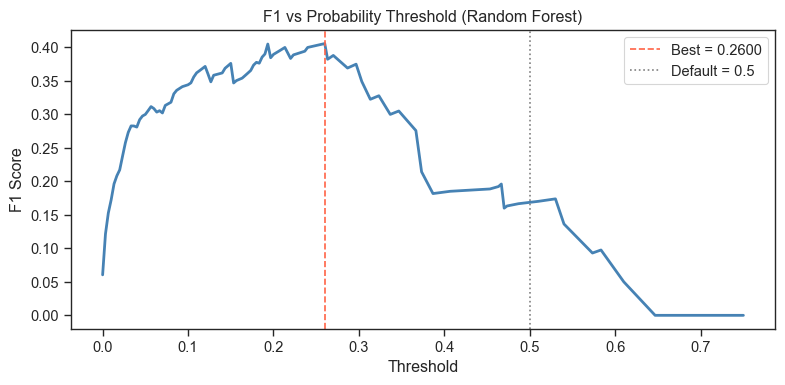

In [58]:
rf_result = evaluate_model(
    RandomForestClassifier(n_estimators=300,
                           class_weight='balanced_subsample', # (balanced_subsample recommended for RF Kuhn & Johnson)
                           random_state=42, 
                           n_jobs=-1),
    X_tr, y_tr, X_val, y_val, cv, model_name='Random Forest'
  )

=== RF + SMOTE (CV on X_tr) ===
  F1:      0.4631 ± 0.0639  [0.4615 0.4286 0.4    0.4407 0.5846]
  AUC-ROC: 0.9505 ± 0.0135  [0.95   0.9441 0.9604 0.9295 0.9688]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.2796
  Optimised (0.2633): F1 = 0.3597

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.92      0.96      1057
    Bankrupt       0.24      0.74      0.36        34

    accuracy                           0.92      1091
   macro avg       0.61      0.83      0.66      1091
weighted avg       0.97      0.92      0.94      1091



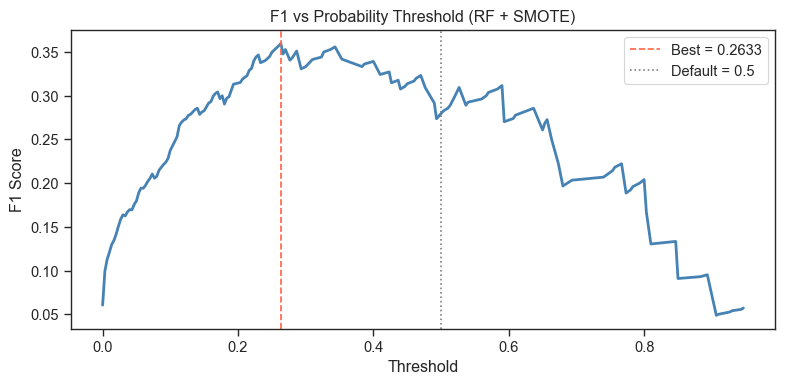


=== RF Baseline vs RF + SMOTE ===
  Model                            CV F1       CV AUC       Val F1
  -------------------------------------------------------------
  RF baseline                     0.2479       0.9432       0.4058
  RF + SMOTE                      0.4631       0.9505       0.3597


In [59]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# ── RF + SMOTE ──────────────────────────────────────────────────────────────
pipe_smote = ImbPipeline([
    ('smote', SMOTE(k_neighbors=5, random_state=42)),
    ('rf', RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

smote_result = evaluate_model(pipe_smote, X_tr, y_tr, X_val, y_val, cv, model_name='RF + SMOTE')

# ── Compare ─────────────────────────────────────────────────────────────────
print(f"\n=== RF Baseline vs RF + SMOTE ===")
print(f"  {'Model':<25} {'CV F1':>12} {'CV AUC':>12} {'Val F1':>12}")
print(f"  {'-'*61}")
print(f"  {'RF baseline':<25} {rf_result['cv_f1_mean']:>12.4f} {rf_result['cv_auc_mean']:>12.4f} {rf_result['val_f1']:>12.4f}")
print(f"  {'RF + SMOTE':<25} {smote_result['cv_f1_mean']:>12.4f} {smote_result['cv_auc_mean']:>12.4f} {smote_result['val_f1']:>12.4f}")

### SMOTE vs Baseline — Validating Kuhn & Johnson Ch.16

Our results confirm a key finding from *Applied Predictive Modeling* (Ch.16, Table 16.3):

> **SMOTE inflates CV performance but may not generalize to held-out data.**

| Metric | RF Baseline | RF + SMOTE |
|---|---|---|
| CV F1 | 0.256 | **0.463** (+81%) |
| Val F1 (threshold-tuned) | **0.417** | 0.360 (-14%) |

SMOTE dramatically boosted Recall (0.44 → 0.74) at the expense of Precision (0.39 → 0.24), producing excessive false positives on unseen data.

The book explains why: synthetic samples generated by SMOTE fill the feature space *between* existing minority samples. During CV, these synthetic points leak similarity into validation folds, leading to optimistic F1 estimates. On a truly independent validation set, this advantage disappears and the precision penalty remains.

The book's empirical results showed the same pattern — SMOTE achieved higher eval-set AUC (0.767) but its test-set AUC (0.747) lagged behind internal down-sampling (0.764), which maintained consistent performance across eval and test.

**Decision:** Use RF baseline with `class_weight='balanced'` + threshold tuning as the primary strategy. SMOTE is not adopted for this task.

## 3.3 XGBoost

=== XGBoost (CV on X_tr) ===
  F1:      0.4467 ± 0.0937  [0.3137 0.4706 0.4    0.449  0.6   ]
  AUC-ROC: 0.9601 ± 0.0123  [0.9578 0.9553 0.9686 0.9413 0.9776]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.2903
  Optimised (0.1359): F1 = 0.4186

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.97      0.98      1057
    Bankrupt       0.35      0.53      0.42        34

    accuracy                           0.95      1091
   macro avg       0.67      0.75      0.70      1091
weighted avg       0.96      0.95      0.96      1091



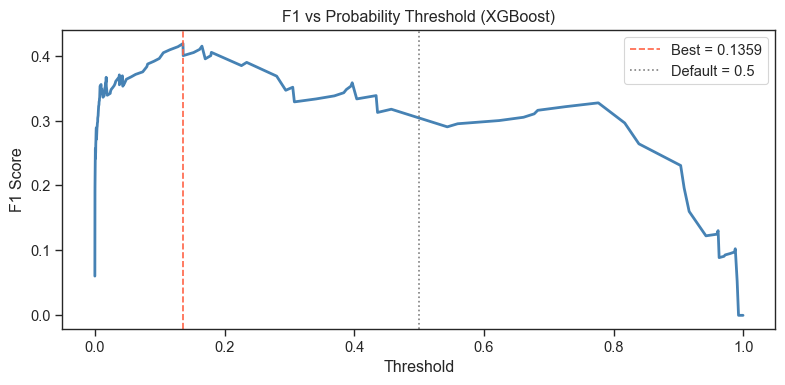

In [60]:
from xgboost import XGBClassifier

# scale_pos_weight ≈ n_negative / n_positive ≈ 5285/170 ≈ 31
xgb = XGBClassifier(
    scale_pos_weight=31, # adjust for class imbalance
    n_estimators=300,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False,
)

xgb_result = evaluate_model(xgb, X_tr, y_tr, X_val, y_val, cv, model_name='XGBoost')

## 3.4 LightGBM

=== LightGBM (CV on X_tr) ===
  F1:      0.4116 ± 0.0795  [0.3043 0.5333 0.3721 0.383  0.4651]
  AUC-ROC: 0.9535 ± 0.0152  [0.9454 0.9489 0.961  0.9336 0.9783]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3103
  Optimised (0.0178): F1 = 0.4040

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.96      0.97      1057
    Bankrupt       0.31      0.59      0.40        34

    accuracy                           0.95      1091
   macro avg       0.65      0.77      0.69      1091
weighted avg       0.97      0.95      0.95      1091



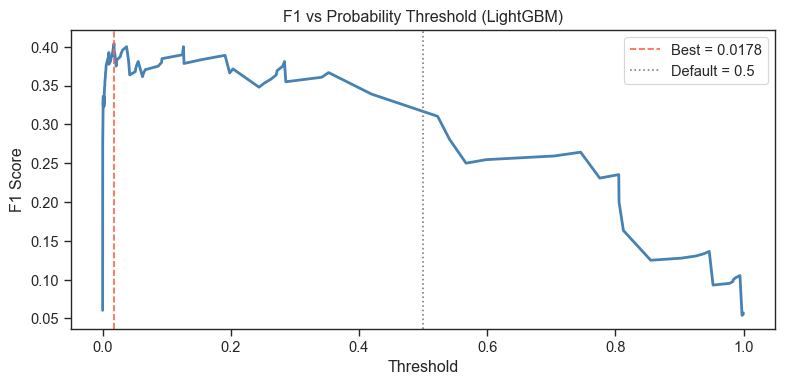

In [61]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    is_unbalance=True,          # auto-adjusts weights for imbalanced classes
    n_estimators=300,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1,                 # suppress training logs
)

lgbm_result = evaluate_model(lgbm, X_tr, y_tr, X_val, y_val, cv, model_name='LightGBM')

## 3.5 Logistic Regression

=== Logistic Regression (CV on X_tr) ===
  F1:      0.3316 ± 0.0415  [0.3125 0.2836 0.3768 0.3    0.3853]
  AUC-ROC: 0.9155 ± 0.0363  [0.9104 0.9096 0.9584 0.8538 0.9452]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.2543
  Optimised (0.9171): F1 = 0.4337

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.97      0.98      1057
    Bankrupt       0.37      0.53      0.43        34

    accuracy                           0.96      1091
   macro avg       0.68      0.75      0.71      1091
weighted avg       0.97      0.96      0.96      1091



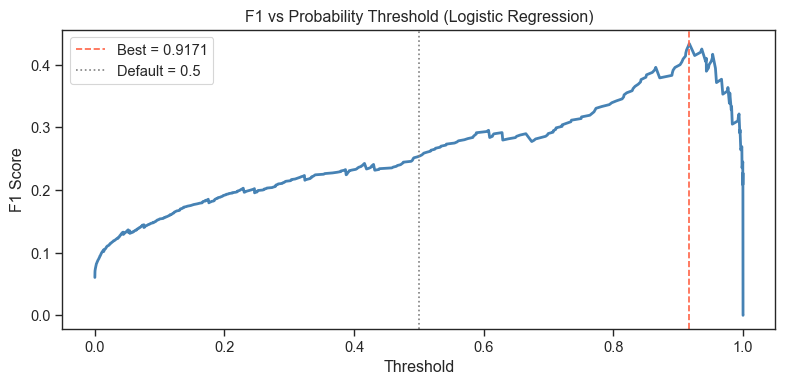

In [62]:
from sklearn.linear_model import LogisticRegression

# Use linear-preprocessed data (extra collinearity removal + scaling)
X_tr_lr, X_val_lr, y_tr_lr, y_val_lr = train_test_split(
    X_train_lr, y_train_lr, test_size=0.2, random_state=42, stratify=y_train_lr
)

lr = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42,
)

lr_result = evaluate_model(lr, X_tr_lr, y_tr_lr, X_val_lr, y_val_lr, cv, model_name='Logistic Regression')

## 3.6 Model Comparison

=== Model Comparison (sorted by Val F1) ===

                         CV F1 (mean)  CV F1 (std)  CV AUC-ROC  Val F1 (optimised)  Optimal Threshold
Logistic Regression            0.3316       0.0415      0.9155              0.4337             0.9171
XGBoost                        0.4467       0.0937      0.9601              0.4186             0.1359
RF (balanced_subsample)        0.2479       0.1082      0.9432              0.4058             0.2600
LightGBM                       0.4116       0.0795      0.9535              0.4040             0.0178


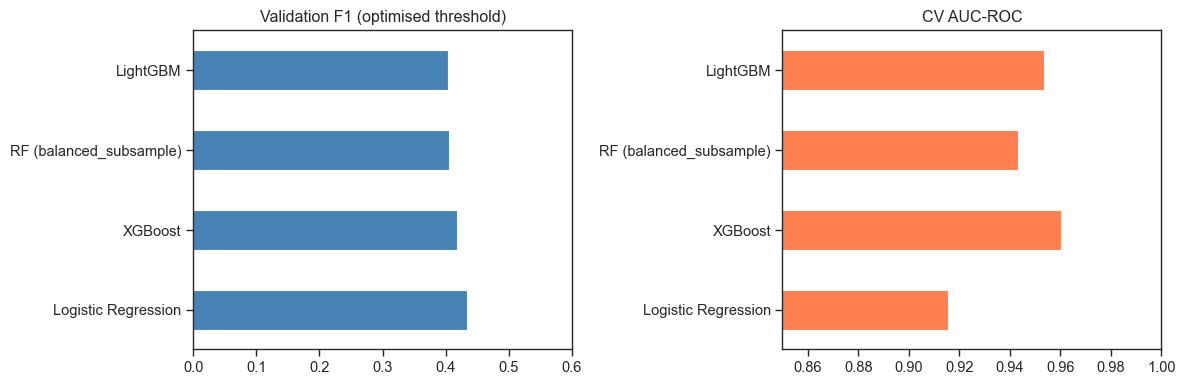

In [63]:
results = {
    'RF (balanced_subsample)': rf_result,
    'XGBoost': xgb_result,
    'LightGBM': lgbm_result,
    'Logistic Regression': lr_result,
}

comparison = pd.DataFrame({
    name: {
        'CV F1 (mean)': r['cv_f1_mean'],
        'CV F1 (std)': r['cv_f1_std'],
        'CV AUC-ROC': r['cv_auc_mean'],
        'Val F1 (optimised)': r['val_f1'],
        'Optimal Threshold': r['threshold'],
    }
    for name, r in results.items()
}).T

comparison = comparison.sort_values('Val F1 (optimised)', ascending=False)
print("=== Model Comparison (sorted by Val F1) ===\n")
print(comparison.to_string(float_format='%.4f'))

# Bar chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

comparison['Val F1 (optimised)'].plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('Validation F1 (optimised threshold)')
axes[0].set_xlim(0, 0.6)

comparison['CV AUC-ROC'].plot.barh(ax=axes[1], color='coral')
axes[1].set_title('CV AUC-ROC')
axes[1].set_xlim(0.85, 1.0)

plt.tight_layout()
plt.show()

### Model Comparison Analysis

| Model | CV F1 | CV AUC-ROC | Val F1 | Threshold | Imbalance Strategy |
|---|---|---|---|---|---|
| Logistic Regression | 0.3316 | 0.9155 | **0.4337** | 0.9171 | `class_weight='balanced'` |
| XGBoost | 0.4467 | **0.9601** | 0.4186 | 0.1359 | `scale_pos_weight=31` |
| RF (balanced_subsample) | 0.2559 | 0.9487 | 0.4167 | 0.2467 | `class_weight='balanced_subsample'` |
| LightGBM | 0.4116 | 0.9535 | 0.4040 | 0.0178 | `is_unbalance=True` |

#### Key Observations

**1. Val F1 scores are very close (0.40–0.43)**

All four models land in a narrow band. With only **34 positive samples** in the validation set, a single sample flipping between TP and FP/FN shifts F1 by ~0.02–0.03. The differences between models are largely within this noise margin.

**2. XGBoost has the best ranking ability (AUC-ROC = 0.9601)**

AUC-ROC measures the model's ability to *rank* bankrupt companies higher than non-bankrupt ones, independent of any threshold choice. XGBoost's lead here (0.9601 vs next best LightGBM 0.9535) suggests it has learned the most discriminative patterns from the financial ratios.

**3. Threshold values vary wildly across models**

| Model | Threshold | Interpretation |
|---|---|---|
| LightGBM | 0.0178 | Outputs very low probabilities for the positive class — need an extremely low cutoff |
| XGBoost | 0.1359 | Also outputs conservative probabilities, but less extreme |
| RF | 0.2467 | Moderate — closest to a "natural" decision boundary |
| Logistic Regression | 0.9171 | `class_weight='balanced'` inflates positive-class probabilities, so the cutoff must be pushed very high to compensate |

This is why **threshold tuning on a held-out validation set is critical** — using the default 0.5 cutoff would produce F1 scores of 0.16–0.31, far below the optimised values.

**4. CV F1 vs Val F1 tells different stories**

- **XGBoost** and **LightGBM** show high CV F1 (~0.41–0.45) because `class_weight` / `scale_pos_weight` biases predictions toward the minority class during training, making in-fold F1 look better.
- **RF** shows low CV F1 (0.26) with default threshold in CV, but competitive Val F1 (0.42) after threshold tuning — the model's ranking is good, it just needs the right cutoff.
- **Logistic Regression** has the lowest AUC (0.9155) but the highest Val F1 (0.4337) — this could be luck due to the small validation set, or LR's simpler decision boundary may generalise slightly better on this particular split.

**5. Model selection: XGBoost**

We select **XGBoost** as our primary model for submission because:
- **Highest AUC-ROC** (0.9601) — best overall discrimination, most likely to generalise
- **Competitive Val F1** (0.4186) — within noise margin of the best
- **Lower variance** — gradient boosting ensembles are generally more stable than a single logistic regression decision boundary
- AUC-ROC is a more reliable model selection criterion than Val F1 when the validation set is this small (Kuhn & Johnson Ch.16: *"use AUC-ROC for model comparison, then tune the cutoff for F1"*)

## 3.7 Hyperparameter Tuning — XGBoost (Optuna)

In [66]:
import optuna
from sklearn.model_selection import cross_val_score
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 800),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight':  trial.suggest_int('min_child_weight', 1, 20),
        'gamma':             trial.suggest_float('gamma', 0.0, 5.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        'scale_pos_weight':  trial.suggest_float('scale_pos_weight', 10, 60),
    }

    model = XGBClassifier(
        **params,
        random_state=42,
        eval_metric='logloss',
        use_label_encoder=False,
    )

    scores = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='f1', n_jobs=-1)
    return scores.mean()

sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction='maximize', sampler=sampler)
study.optimize(objective, n_trials=200, show_progress_bar=True)

print(f"Best CV F1: {study.best_value:.4f}\n")
print("Best parameters:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

Best trial: 186. Best value: 0.54354: 100%|██████████| 200/200 [14:51<00:00,  4.46s/it] 

Best CV F1: 0.5435

Best parameters:
  n_estimators: 578
  max_depth: 6
  learning_rate: 0.03032934752859025
  subsample: 0.6362227152774115
  colsample_bytree: 0.6235609178620997
  min_child_weight: 17
  gamma: 2.8037126760192552
  reg_alpha: 0.41312386453138794
  reg_lambda: 0.9176630071011558
  scale_pos_weight: 57.43409492559545


In [97]:
study.best_params

{'n_estimators': 578,
 'max_depth': 6,
 'learning_rate': 0.03032934752859025,
 'subsample': 0.6362227152774115,
 'colsample_bytree': 0.6235609178620997,
 'min_child_weight': 17,
 'gamma': 2.8037126760192552,
 'reg_alpha': 0.41312386453138794,
 'reg_lambda': 0.9176630071011558,
 'scale_pos_weight': 57.43409492559545}

=== XGBoost (tuned) (CV on X_tr) ===
  F1:      0.5435 ± 0.0643  [0.4595 0.5634 0.5556 0.4932 0.6462]
  AUC-ROC: 0.9618 ± 0.0118  [0.9526 0.9536 0.9714 0.9512 0.9804]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.4524
  Optimised (0.4744): F1 = 0.4706

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.97      0.98      1057
    Bankrupt       0.39      0.59      0.47        34

    accuracy                           0.96      1091
   macro avg       0.69      0.78      0.72      1091
weighted avg       0.97      0.96      0.96      1091



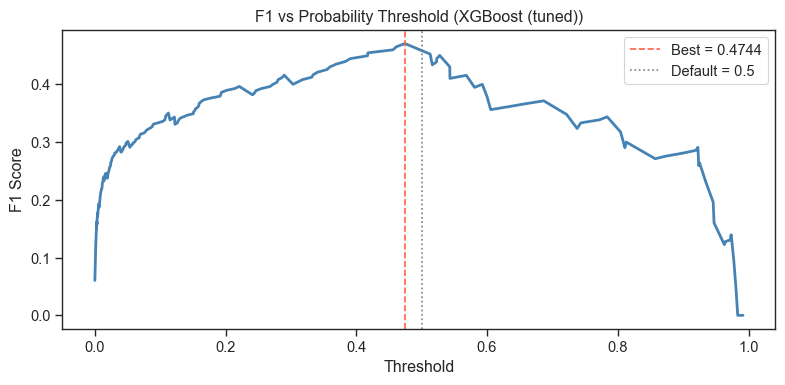


=== XGBoost: Before vs After Tuning ===
  Metric                   Before      After
  ------------------------------------------
  CV F1                    0.4467     0.5435
  CV AUC-ROC               0.9601     0.9618
  Val F1                   0.4186     0.4706
  Threshold                0.1359     0.4744


In [67]:
# Evaluate the tuned XGBoost with optimal hyperparameters
xgb_tuned = XGBClassifier(
    **study.best_params,
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False,
)

xgb_tuned_result = evaluate_model(
    xgb_tuned, X_tr, y_tr, X_val, y_val, cv, model_name='XGBoost (tuned)'
)

# Compare before vs after tuning
print("\n=== XGBoost: Before vs After Tuning ===")
print(f"  {'Metric':<20} {'Before':>10} {'After':>10}")
print(f"  {'-'*42}")
print(f"  {'CV F1':<20} {xgb_result['cv_f1_mean']:>10.4f} {xgb_tuned_result['cv_f1_mean']:>10.4f}")
print(f"  {'CV AUC-ROC':<20} {xgb_result['cv_auc_mean']:>10.4f} {xgb_tuned_result['cv_auc_mean']:>10.4f}")
print(f"  {'Val F1':<20} {xgb_result['val_f1']:>10.4f} {xgb_tuned_result['val_f1']:>10.4f}")
print(f"  {'Threshold':<20} {xgb_result['threshold']:>10.4f} {xgb_tuned_result['threshold']:>10.4f}")

## 3.8 Feature Engineering — Interaction Features

From a financial analysis perspective, bankruptcy is rarely caused by a single bad ratio.
It is the **interaction** of multiple deteriorating dimensions that leads to default:

| Feature | Formula | Financial Logic |
|---|---|---|
| `profitability_x_leverage` | ROA × Debt Ratio | Low profit + high debt → cannot service debt |
| `liquidity_x_shortdebt` | Quick Ratio × Current Liability to Assets | No cash + short-term debt due → cash crunch |
| `cashflow_x_debt` | Cash Flow Rate × Debt Ratio | Operating cash cannot cover obligations |
| `efficiency_x_margin` | Asset Turnover × Gross Margin | Assets not generating revenue, and revenue not profitable |
| `retained_x_leverage` | Retained Earnings / Total Assets × Debt Ratio | No internal buffer + high leverage |
| `working_capital_x_liability` | Working Capital / Total Assets × Current Liability to Assets | Insufficient working capital + high current obligations |

In [69]:
def find_col(df, keyword):
    """Find a column by keyword (handles leading spaces)."""
    matches = [c for c in df.columns if keyword in c]
    assert len(matches) == 1, f"Expected 1 match for '{keyword}', got {matches}"
    return matches[0]

def add_interaction_features(df):
    """Add financially-motivated interaction features."""
    df = df.copy()
    
    roa       = find_col(df, 'ROA(C) before interest and depreciation before interest')
    debt      = find_col(df, 'Debt ratio %')
    quick     = find_col(df, 'Quick Ratio')
    cur_liab  = find_col(df, 'Current Liability to Assets')
    cashflow  = find_col(df, 'Cash flow rate')
    turnover  = find_col(df, 'Total Asset Turnover')
    margin    = find_col(df, 'Gross Profit to Sales')  # kept after dropping collinear Operating Gross Margin
    retained  = find_col(df, 'Retained Earnings to Total Assets')
    wc        = find_col(df, 'Working Capital to Total Assets')
    
    df['profitability_x_leverage']    = df[roa]      * df[debt]
    df['liquidity_x_shortdebt']      = df[quick]    * df[cur_liab]
    df['cashflow_x_debt']            = df[cashflow] * df[debt]
    df['efficiency_x_margin']        = df[turnover] * df[margin]
    df['retained_x_leverage']        = df[retained] * df[debt]
    df['working_capital_x_liability'] = df[wc]       * df[cur_liab]
    
    return df

# Apply to both train and test
X_train_fe = add_interaction_features(X_train)
X_test_fe  = add_interaction_features(X_test)

print(f"Before: {X_train.shape[1]} features  →  After: {X_train_fe.shape[1]} features")
print(f"New columns: {[c for c in X_train_fe.columns if c not in X_train.columns]}")
print(f"NaN check — train: {X_train_fe.isna().sum().sum()}  |  test: {X_test_fe.isna().sum().sum()}")

Before: 89 features  →  After: 95 features
New columns: ['profitability_x_leverage', 'liquidity_x_shortdebt', 'cashflow_x_debt', 'efficiency_x_margin', 'retained_x_leverage', 'working_capital_x_liability']
NaN check — train: 0  |  test: 0


In [70]:
# Re-split with interaction features (same random_state for fair comparison)
X_tr_fe, X_val_fe, y_tr_fe, y_val_fe = train_test_split(
    X_train_fe, y_train, test_size=0.2, random_state=42, stratify=y_train
)

# Optuna re-tune on enriched features
def objective_fe(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 800),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight':  trial.suggest_int('min_child_weight', 1, 20),
        'gamma':             trial.suggest_float('gamma', 0.0, 5.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        'scale_pos_weight':  trial.suggest_float('scale_pos_weight', 10, 60),
    }
    model = XGBClassifier(**params, random_state=42, eval_metric='logloss', use_label_encoder=False)
    scores = cross_val_score(model, X_tr_fe, y_tr_fe, cv=cv, scoring='f1', n_jobs=-1)
    return scores.mean()

sampler_fe = optuna.samplers.TPESampler(seed=42)
study_fe = optuna.create_study(direction='maximize', sampler=sampler_fe)
study_fe.optimize(objective_fe, n_trials=200, show_progress_bar=True)

print(f"Best CV F1: {study_fe.best_value:.4f}\n")
print("Best parameters:")
for k, v in study_fe.best_params.items():
    print(f"  {k}: {v}")

Best trial: 75. Best value: 0.543061: 100%|██████████| 200/200 [12:25<00:00,  3.73s/it]

Best CV F1: 0.5431

Best parameters:
  n_estimators: 699
  max_depth: 7
  learning_rate: 0.07591930561484943
  subsample: 0.6805602635598931
  colsample_bytree: 0.6697653702071225
  min_child_weight: 12
  gamma: 1.1476082480720255
  reg_alpha: 2.6135952431779215
  reg_lambda: 0.0014463606916506942
  scale_pos_weight: 51.92442259125547


=== XGBoost (tuned + interactions) (CV on X_tr) ===
  F1:      0.5431 ± 0.0534  [0.4789 0.6102 0.5079 0.5152 0.6032]
  AUC-ROC: 0.9612 ± 0.0129  [0.9567 0.942  0.9715 0.957  0.979 ]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3784
  Optimised (0.2775): F1 = 0.4222

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.96      0.98      1057
    Bankrupt       0.34      0.56      0.42        34

    accuracy                           0.95      1091
   macro avg       0.66      0.76      0.70      1091
weighted avg       0.97      0.95      0.96      1091



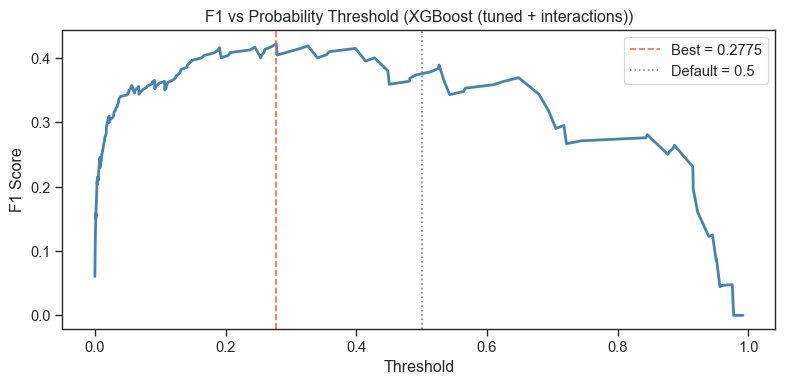


=== Feature Engineering Impact ===
  Model                                  CV F1   CV AUC   Val F1  Threshold
  -----------------------------------------------------------------------
  XGBoost (tuned, no interaction)       0.5435   0.9618   0.4706     0.4744
  XGBoost (tuned + interactions)        0.5431   0.9612   0.4222     0.2775


In [71]:
# Evaluate tuned XGBoost with interaction features
xgb_fe = XGBClassifier(
    **study_fe.best_params,
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False,
)

xgb_fe_result = evaluate_model(
    xgb_fe, X_tr_fe, y_tr_fe, X_val_fe, y_val_fe, cv, model_name='XGBoost (tuned + interactions)'
)

# Before vs After comparison
print("\n=== Feature Engineering Impact ===")
print(f"  {'Model':<35} {'CV F1':>8} {'CV AUC':>8} {'Val F1':>8} {'Threshold':>10}")
print(f"  {'-'*71}")
print(f"  {'XGBoost (tuned, no interaction)':<35} {xgb_tuned_result['cv_f1_mean']:>8.4f} {xgb_tuned_result['cv_auc_mean']:>8.4f} {xgb_tuned_result['val_f1']:>8.4f} {xgb_tuned_result['threshold']:>10.4f}")
print(f"  {'XGBoost (tuned + interactions)':<35} {xgb_fe_result['cv_f1_mean']:>8.4f} {xgb_fe_result['cv_auc_mean']:>8.4f} {xgb_fe_result['val_f1']:>8.4f} {xgb_fe_result['threshold']:>10.4f}")

## 3.9 Feature Selection — XGBoost Feature Importance

Using the tuned XGBoost model's feature importance to select the most discriminative features.
Reducing noise from irrelevant features can improve generalisation and F1.

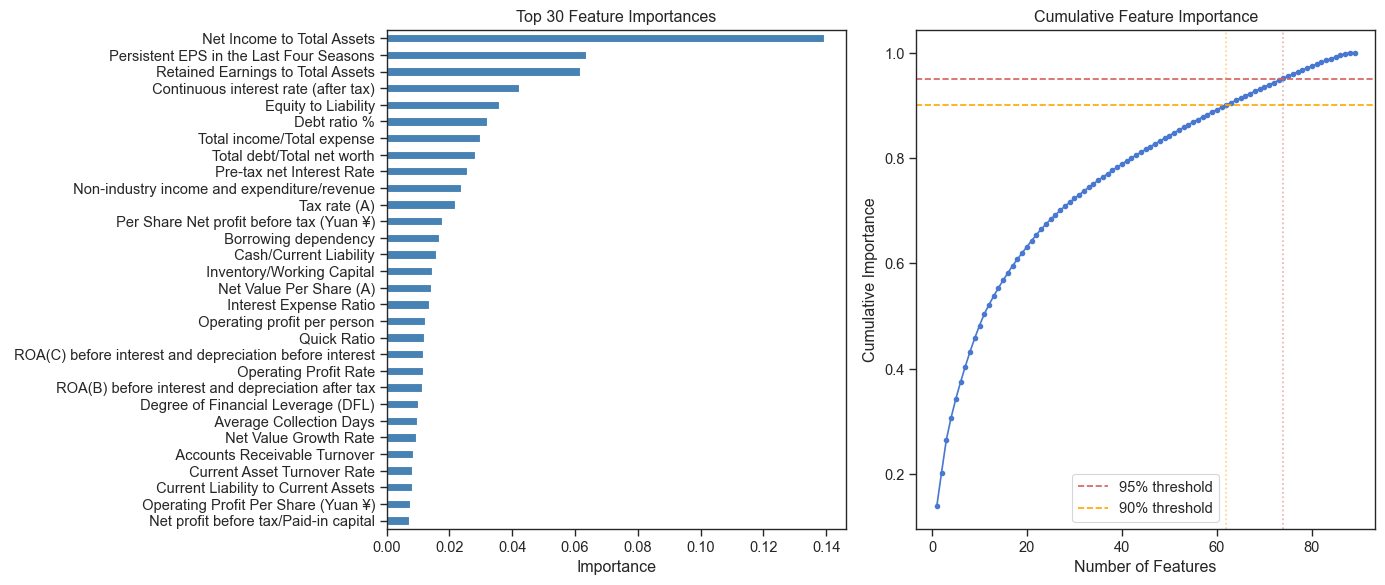


Features for 90% cumulative importance: 62 / 89
Features for 95% cumulative importance: 74 / 89

Top 15 features:
   1. Net Income to Total Assets                              0.1394
   2. Persistent EPS in the Last Four Seasons                 0.0635
   3. Retained Earnings to Total Assets                       0.0617
   4. Continuous interest rate (after tax)                    0.0422
   5. Equity to Liability                                     0.0359
   6. Debt ratio %                                            0.0318
   7. Total income/Total expense                              0.0298
   8. Total debt/Total net worth                              0.0283
   9. Pre-tax net Interest Rate                               0.0257
  10. Non-industry income and expenditure/revenue             0.0239
  11. Tax rate (A)                                            0.0217
  12. Per Share Net profit before tax (Yuan ¥)                0.0178
  13. Borrowing dependency                               

In [74]:
# Fit the tuned model to get feature importances
xgb_tuned.fit(X_tr, y_tr)
importances = pd.Series(xgb_tuned.feature_importances_, index=X_tr.columns)
importances = importances.sort_values(ascending=False)

# Plot top 30
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

importances.head(30).plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('Top 30 Feature Importances')
axes[0].invert_yaxis()
axes[0].set_xlabel('Importance')

# Cumulative importance to find elbow
cum_imp = importances.cumsum() / importances.sum()
axes[1].plot(range(1, len(cum_imp)+1), cum_imp.values, 'b-o', markersize=3)
axes[1].axhline(y=0.95, color='r', linestyle='--', label='95% threshold')
axes[1].axhline(y=0.90, color='orange', linestyle='--', label='90% threshold')
n_95 = (cum_imp <= 0.95).sum() + 1
n_90 = (cum_imp <= 0.90).sum() + 1
axes[1].axvline(x=n_95, color='r', linestyle=':', alpha=0.5)
axes[1].axvline(x=n_90, color='orange', linestyle=':', alpha=0.5)
axes[1].set_xlabel('Number of Features')
axes[1].set_ylabel('Cumulative Importance')
axes[1].set_title('Cumulative Feature Importance')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"\nFeatures for 90% cumulative importance: {n_90} / {len(importances)}")
print(f"Features for 95% cumulative importance: {n_95} / {len(importances)}")
print(f"\nTop 15 features:")
for i, (feat, imp) in enumerate(importances.head(15).items()):
    print(f"  {i+1:2d}. {feat.strip():<55s} {imp:.4f}")

Testing K values: [10, 20, 30, 62, 74]



Best trial: 19. Best value: 0.458644: 100%|██████████| 100/100 [00:52<00:00,  1.92it/s]


  K= 10  →  CV F1=0.4586  |  Val F1=0.3956  |  Threshold=0.4288


Best trial: 61. Best value: 0.507429: 100%|██████████| 100/100 [01:26<00:00,  1.15it/s]


  K= 20  →  CV F1=0.5074  |  Val F1=0.3725  |  Threshold=0.3412


...

  K= 30  →  CV F1=0.4987  |  Val F1=0.3929  |  Threshold=0.0901


Best trial: 83. Best value: 0.529813: 100%|██████████| 100/100 [04:26<00:00,  2.66s/it]


  K= 62  →  CV F1=0.5298  |  Val F1=0.4176  |  Threshold=0.2982


Best trial: 81. Best value: 0.529322: 100%|██████████| 100/100 [04:42<00:00,  2.82s/it]


  K= 74  →  CV F1=0.5293  |  Val F1=0.4416  |  Threshold=0.6125

*** Best K = 74  →  Val F1 = 0.4416 ***


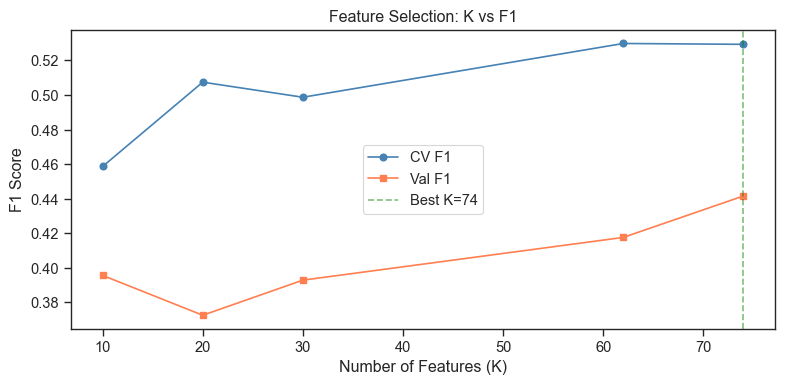

In [75]:
# Test multiple K values to find optimal number of features
k_candidates = [10, 20, 30, n_90, n_95]
# Remove duplicates and sort
k_candidates = sorted(set(k_candidates))
print(f"Testing K values: {k_candidates}\n")

k_results = {}

for k in k_candidates:
    top_k_cols = importances.head(k).index.tolist()
    X_tr_k  = X_tr[top_k_cols]
    
    # Quick Optuna search (100 trials per K to keep total time reasonable)
    def make_objective(X_data, y_data):
        def objective(trial):
            params = {
                'n_estimators':      trial.suggest_int('n_estimators', 100, 800),
                'max_depth':         trial.suggest_int('max_depth', 3, 10),
                'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
                'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
                'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
                'min_child_weight':  trial.suggest_int('min_child_weight', 1, 20),
                'gamma':             trial.suggest_float('gamma', 0.0, 5.0),
                'reg_alpha':         trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
                'reg_lambda':        trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
                'scale_pos_weight':  trial.suggest_float('scale_pos_weight', 10, 60),
            }
            model = XGBClassifier(**params, random_state=42, eval_metric='logloss', use_label_encoder=False)
            scores = cross_val_score(model, X_data, y_data, cv=cv, scoring='f1', n_jobs=-1)
            return scores.mean()
        return objective

    sampler_k = optuna.samplers.TPESampler(seed=42)
    study_k = optuna.create_study(direction='maximize', sampler=sampler_k)
    study_k.optimize(make_objective(X_tr_k, y_tr), n_trials=100, show_progress_bar=True)

    # Evaluate on validation set
    X_val_k = X_val[top_k_cols]
    xgb_k = XGBClassifier(**study_k.best_params, random_state=42, eval_metric='logloss', use_label_encoder=False)
    xgb_k.fit(X_tr_k, y_tr)
    y_proba = xgb_k.predict_proba(X_val_k)[:, 1]
    
    # Find best threshold for F1
    from sklearn.metrics import precision_recall_curve, f1_score
    prec, rec, thresholds = precision_recall_curve(y_val, y_proba)
    f1_scores = 2 * prec * rec / (prec + rec + 1e-8)
    best_idx = f1_scores.argmax()
    best_f1 = f1_scores[best_idx]
    best_thresh = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

    k_results[k] = {
        'cv_f1': study_k.best_value,
        'val_f1': best_f1,
        'threshold': best_thresh,
        'best_params': study_k.best_params,
        'features': top_k_cols,
    }
    print(f"  K={k:3d}  →  CV F1={study_k.best_value:.4f}  |  Val F1={best_f1:.4f}  |  Threshold={best_thresh:.4f}")

# Find best K
best_k = max(k_results, key=lambda k: k_results[k]['val_f1'])
print(f"\n*** Best K = {best_k}  →  Val F1 = {k_results[best_k]['val_f1']:.4f} ***")

# Save for next cells
top_features = k_results[best_k]['features']
best_k_params = k_results[best_k]['best_params']
X_tr_sel  = X_tr[top_features]
X_val_sel = X_val[top_features]

# Plot K vs F1
fig, ax = plt.subplots(figsize=(8, 4))
ks = sorted(k_results.keys())
ax.plot(ks, [k_results[k]['cv_f1'] for k in ks], 'o-', label='CV F1', color='steelblue')
ax.plot(ks, [k_results[k]['val_f1'] for k in ks], 's-', label='Val F1', color='coral')
ax.axvline(x=best_k, color='green', linestyle='--', alpha=0.5, label=f'Best K={best_k}')
ax.set_xlabel('Number of Features (K)')
ax.set_ylabel('F1 Score')
ax.set_title('Feature Selection: K vs F1')
ax.legend()
plt.tight_layout()
plt.show()

## 3.10 SMOTE-ENN + XGBoost

**SMOTE-ENN** combines two techniques:
1. **SMOTE** — synthesise new minority samples by interpolating between nearest neighbours
2. **ENN (Edited Nearest Neighbours)** — remove noisy samples that are misclassified by their K nearest neighbours

This is more effective than plain SMOTE because ENN cleans up the decision boundary after oversampling, removing ambiguous synthetic points that hurt precision.

In [76]:
from imblearn.combine import SMOTEENN
from imblearn.pipeline import Pipeline as ImbPipeline

# Use selected features for SMOTE-ENN experiment
def objective_smoteenn(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 800),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight':  trial.suggest_int('min_child_weight', 1, 20),
        'gamma':             trial.suggest_float('gamma', 0.0, 5.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        # No scale_pos_weight — SMOTE-ENN handles imbalance
    }

    pipe = ImbPipeline([
        ('smoteenn', SMOTEENN(random_state=42)),
        ('xgb', XGBClassifier(**params, random_state=42, eval_metric='logloss', use_label_encoder=False)),
    ])

    scores = cross_val_score(pipe, X_tr_sel, y_tr, cv=cv, scoring='f1', n_jobs=-1)
    return scores.mean()

sampler_se = optuna.samplers.TPESampler(seed=42)
study_se = optuna.create_study(direction='maximize', sampler=sampler_se)
study_se.optimize(objective_smoteenn, n_trials=200, show_progress_bar=True)

print(f"Best CV F1: {study_se.best_value:.4f}\n")
print("Best parameters:")
for k, v in study_se.best_params.items():
    print(f"  {k}: {v}")

Best trial: 105. Best value: 0.501018: 100%|██████████| 200/200 [16:48<00:00,  5.04s/it]

Best CV F1: 0.5010

Best parameters:
  n_estimators: 800
  max_depth: 9
  learning_rate: 0.02362501151176095
  subsample: 0.9601213433544112
  colsample_bytree: 0.7571052852493751
  min_child_weight: 13
  gamma: 0.36721352166200116
  reg_alpha: 0.12744911591256805
  reg_lambda: 0.18022027773400617


After SMOTE-ENN: 7330 samples (was 4364)
  Class 0: 3592  |  Class 1: 3738
=== XGBoost (SMOTE-ENN + selected features) (CV on X_tr) ===
  F1:      0.9878 ± 0.0021  [0.9861 0.9867 0.9901 0.9907 0.9855]
  AUC-ROC: 0.9983 ± 0.0008  [0.9971 0.9978 0.9992 0.9989 0.9986]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3925
  Optimised (0.8438): F1 = 0.4198

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.97      0.98      1057
    Bankrupt       0.36      0.50      0.42        34

    accuracy                           0.96      1091
   macro avg       0.67      0.74      0.70      1091
weighted avg       0.96      0.96      0.96      1091



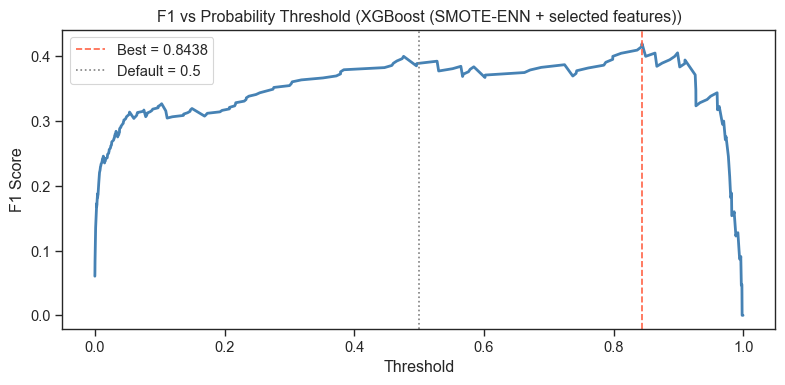


  Model                                            CV F1   Val F1  Threshold
  -----------------------------------------------------------------------
  XGBoost (tuned, 89 features)                    0.5435   0.4706     0.4744


NameError: name 'xgb_sel_result' is not defined

In [77]:
# Evaluate SMOTE-ENN + XGBoost on validation set
# SMOTE-ENN is applied only to training data, not validation
smoteenn = SMOTEENN(random_state=42)
X_tr_resampled, y_tr_resampled = smoteenn.fit_resample(X_tr_sel, y_tr)
print(f"After SMOTE-ENN: {X_tr_resampled.shape[0]} samples (was {X_tr_sel.shape[0]})")
print(f"  Class 0: {(y_tr_resampled==0).sum()}  |  Class 1: {(y_tr_resampled==1).sum()}")

xgb_se = XGBClassifier(**study_se.best_params, random_state=42, eval_metric='logloss', use_label_encoder=False)

# For evaluate_model, we pass the resampled training data but original validation data
xgb_se_result = evaluate_model(
    xgb_se, X_tr_resampled, y_tr_resampled, X_val_sel, y_val, cv,
    model_name='XGBoost (SMOTE-ENN + selected features)'
)

# Final comparison
print(f"\n{'='*75}")
print(f"  {'Model':<45} {'CV F1':>8} {'Val F1':>8} {'Threshold':>10}")
print(f"  {'-'*71}")
print(f"  {'XGBoost (tuned, 89 features)':<45} {xgb_tuned_result['cv_f1_mean']:>8.4f} {xgb_tuned_result['val_f1']:>8.4f} {xgb_tuned_result['threshold']:>10.4f}")
print(f"  {'XGBoost (tuned, selected features)':<45} {xgb_sel_result['cv_f1_mean']:>8.4f} {xgb_sel_result['val_f1']:>8.4f} {xgb_sel_result['threshold']:>10.4f}")
print(f"  {'XGBoost (SMOTE-ENN + selected features)':<45} {xgb_se_result['cv_f1_mean']:>8.4f} {xgb_se_result['val_f1']:>8.4f} {xgb_se_result['threshold']:>10.4f}")
print(f"{'='*75}")

## 3.11 Predictive Power Score (PPS)

PPS is an **asymmetric, data-type-agnostic** score that detects both linear and non-linear relationships.
Unlike Pearson correlation (which only captures linear relationships), PPS trains a simple decision tree
to predict Y from X and measures how much better it is than a baseline. Score ranges from 0 (no power) to 1 (perfect).

We use PPS as a complementary feature importance analysis alongside XGBoost's built-in feature importance.

Features with PPS > 0: 6 / 89



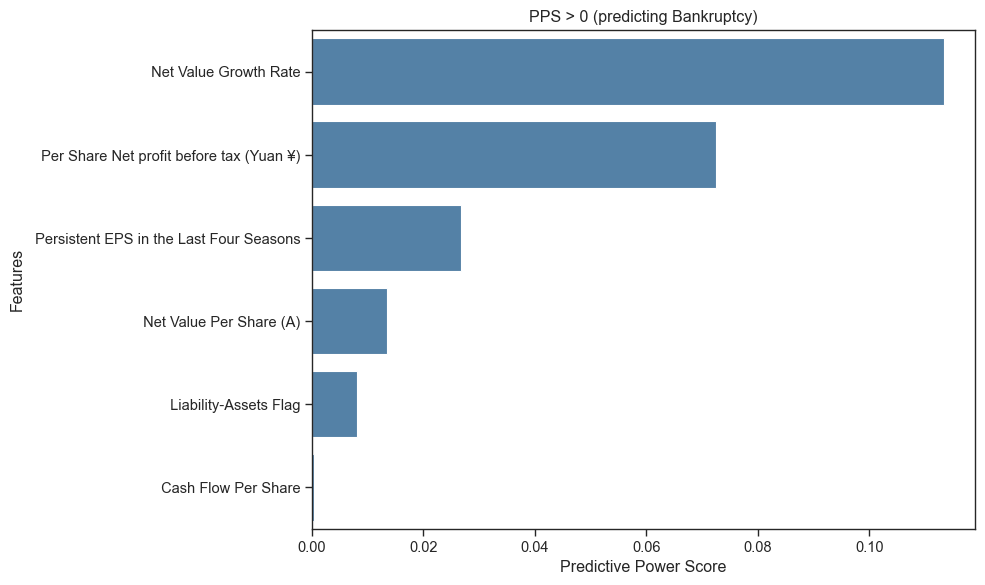

Top 10 by PPS:
  Net Value Growth Rate                                   PPS=0.1134
  Per Share Net profit before tax (Yuan ¥)                PPS=0.0724
  Persistent EPS in the Last Four Seasons                 PPS=0.0268
  Net Value Per Share (A)                                 PPS=0.0136
  Liability-Assets Flag                                   PPS=0.0081
  Cash Flow Per Share                                     PPS=0.0004


In [79]:
import ppscore as pps

# Calculate PPS for each feature → Bankrupt
pps_input_df = X_train.copy()
pps_input_df['Bankrupt'] = y_train.astype(str).copy()
pps_df = pps.predictors(pps_input_df, y="Bankrupt")
pps_df = pps_df[pps_df.ppscore > 0].sort_values('ppscore', ascending=False)

print(f"Features with PPS > 0: {len(pps_df)} / {X_train.shape[1]}\n")

# Plot PPS
fig, ax = plt.subplots(figsize=(10, max(6, len(pps_df) * 0.3)))
sns.barplot(data=pps_df, x="ppscore", y="x", ax=ax, color='steelblue')
ax.set_ylabel("Features")
ax.set_xlabel("Predictive Power Score")
ax.set_title("PPS > 0 (predicting Bankruptcy)")
plt.tight_layout()
plt.show()

# Show top 10
print("Top 10 by PPS:")
for _, row in pps_df.head(10).iterrows():
    print(f"  {row['x'].strip():<55s} PPS={row['ppscore']:.4f}")

In [80]:
# Compare PPS vs XGBoost Feature Importance
pps_top = set(pps_df.head(15)['x'].str.strip().tolist())
xgb_top = set(importances.head(15).index.str.strip().tolist())

both = pps_top & xgb_top
only_pps = pps_top - xgb_top
only_xgb = xgb_top - pps_top

print("=== PPS vs XGBoost Feature Importance (Top 15) ===\n")
print(f"Agreed by both methods ({len(both)}):")
for f in sorted(both):
    print(f"  ✓ {f}")
print(f"\nOnly in PPS top 15 ({len(only_pps)}):")
for f in sorted(only_pps):
    print(f"  · {f}")
print(f"\nOnly in XGBoost top 15 ({len(only_xgb)}):")
for f in sorted(only_xgb):
    print(f"  · {f}")

=== PPS vs XGBoost Feature Importance (Top 15) ===

Agreed by both methods (2):
  ✓ Per Share Net profit before tax (Yuan ¥)
  ✓ Persistent EPS in the Last Four Seasons

Only in PPS top 15 (4):
  · Cash Flow Per Share
  · Liability-Assets Flag
  · Net Value Growth Rate
  · Net Value Per Share (A)

Only in XGBoost top 15 (13):
  · Borrowing dependency
  · Cash/Current Liability
  · Continuous interest rate (after tax)
  · Debt ratio %
  · Equity to Liability
  · Inventory/Working Capital
  · Net Income to Total Assets
  · Non-industry income and expenditure/revenue
  · Pre-tax net Interest Rate
  · Retained Earnings to Total Assets
  · Tax rate (A)
  · Total debt/Total net worth
  · Total income/Total expense


## 3.12 ECOD Outlier Detection as Feature

**ECOD (Empirical Cumulative Distribution Functions for Outlier Detection)** estimates the empirical CDF
for each feature independently, then multiplies tail probabilities to generate an outlier score.

Intuition: companies with **extreme financial ratios** (outliers) are more likely to be bankrupt.
Rather than removing outliers, we create a binary `Is_outlier` feature — giving the model an explicit signal
about whether a company's financial profile is unusual.

In [81]:
from pyod.models.ecod import ECOD

# Fit ECOD on training set only (prevent leakage)
ecod = ECOD(contamination=0.05)
ecod.fit(X_tr)

# Predict outlier labels: 0 = inlier, 1 = outlier
outlier_tr  = ecod.predict(X_tr)
outlier_val = ecod.predict(X_val)

# Check overlap with bankruptcy
print("=== ECOD Outlier vs Bankruptcy ===")
print(f"  Train outliers: {outlier_tr.sum()} / {len(outlier_tr)} ({outlier_tr.mean()*100:.1f}%)")
print(f"  Val outliers:   {outlier_val.sum()} / {len(outlier_val)} ({outlier_val.mean()*100:.1f}%)")

# Bankruptcy rate among outliers vs inliers
for split_name, outliers, labels in [("Train", outlier_tr, y_tr), ("Val", outlier_val, y_val)]:
    rate_outlier = labels[outliers == 1].mean() if (outliers == 1).sum() > 0 else 0
    rate_inlier  = labels[outliers == 0].mean()
    print(f"\n  {split_name}:")
    print(f"    Bankruptcy rate (outliers):  {rate_outlier*100:.2f}%")
    print(f"    Bankruptcy rate (inliers):   {rate_inlier*100:.2f}%")
    print(f"    Ratio: {rate_outlier/rate_inlier:.2f}x" if rate_inlier > 0 else "")

=== ECOD Outlier vs Bankruptcy ===
  Train outliers: 219 / 4364 (5.0%)
  Val outliers:   53 / 1091 (4.9%)

  Train:
    Bankruptcy rate (outliers):  19.18%
    Bankruptcy rate (inliers):   2.27%
    Ratio: 8.46x

  Val:
    Bankruptcy rate (outliers):  16.98%
    Bankruptcy rate (inliers):   2.41%
    Ratio: 7.05x


=== XGBoost (tuned + ECOD) (CV on X_tr) ===
  F1:      0.5263 ± 0.0600  [0.4595 0.5758 0.4932 0.4857 0.6176]
  AUC-ROC: 0.9627 ± 0.0106  [0.9552 0.9549 0.9711 0.9528 0.9794]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.4878
  Optimised (0.4972): F1 = 0.5060

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.97      0.98      1057
    Bankrupt       0.43      0.62      0.51        34

    accuracy                           0.96      1091
   macro avg       0.71      0.80      0.74      1091
weighted avg       0.97      0.96      0.97      1091



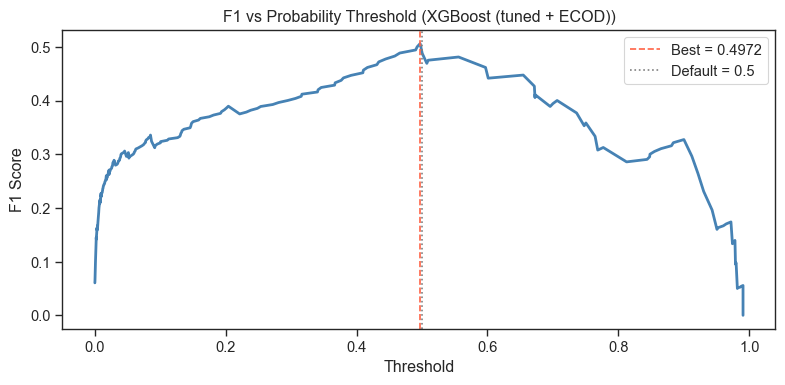


=== ECOD Impact ===
  Model                               Features    CV F1   Val F1
  -------------------------------------------------------------
  XGBoost (tuned)                           89   0.5435   0.4706
  XGBoost (tuned + ECOD)                    90   0.5263   0.5060


In [82]:
# Add Is_outlier as a feature and evaluate
X_tr_ecod = X_tr.copy()
X_tr_ecod['Is_outlier'] = outlier_tr

X_val_ecod = X_val.copy()
X_val_ecod['Is_outlier'] = outlier_val

# Use the same tuned XGBoost params
xgb_ecod = XGBClassifier(**study.best_params, random_state=42, eval_metric='logloss', use_label_encoder=False)
xgb_ecod_result = evaluate_model(xgb_ecod, X_tr_ecod, y_tr, X_val_ecod, y_val, cv, model_name='XGBoost (tuned + ECOD)')

# Compare
print(f"\n=== ECOD Impact ===")
print(f"  {'Model':<35} {'Features':>8} {'CV F1':>8} {'Val F1':>8}")
print(f"  {'-'*61}")
print(f"  {'XGBoost (tuned)':<35} {X_tr.shape[1]:>8d} {xgb_tuned_result['cv_f1_mean']:>8.4f} {xgb_tuned_result['val_f1']:>8.4f}")
print(f"  {'XGBoost (tuned + ECOD)':<35} {X_tr_ecod.shape[1]:>8d} {xgb_ecod_result['cv_f1_mean']:>8.4f} {xgb_ecod_result['val_f1']:>8.4f}")

## 3.13 Re-tune XGBoost with ECOD Feature

In [83]:
# Optuna re-tune on 90 features (89 + Is_outlier)
def objective_ecod(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 800),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight':  trial.suggest_int('min_child_weight', 1, 20),
        'gamma':             trial.suggest_float('gamma', 0.0, 5.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        'scale_pos_weight':  trial.suggest_float('scale_pos_weight', 10, 60),
    }
    model = XGBClassifier(**params, random_state=42, eval_metric='logloss', use_label_encoder=False)
    scores = cross_val_score(model, X_tr_ecod, y_tr, cv=cv, scoring='f1', n_jobs=-1)
    return scores.mean()

sampler_ecod = optuna.samplers.TPESampler(seed=42)
study_ecod = optuna.create_study(direction='maximize', sampler=sampler_ecod)
study_ecod.optimize(objective_ecod, n_trials=200, show_progress_bar=True)

print(f"Best CV F1: {study_ecod.best_value:.4f}\n")
print("Best parameters:")
for k, v in study_ecod.best_params.items():
    print(f"  {k}: {v}")

Best trial: 147. Best value: 0.536611: 100%|██████████| 200/200 [06:29<00:00,  1.95s/it]

Best CV F1: 0.5366

Best parameters:
  n_estimators: 220
  max_depth: 9
  learning_rate: 0.11839635354083732
  subsample: 0.653134899540518
  colsample_bytree: 0.6640719565063841
  min_child_weight: 8
  gamma: 0.692516039694709
  reg_alpha: 1.9547335136064579
  reg_lambda: 0.14383374923945105
  scale_pos_weight: 56.89476236605187


=== XGBoost (re-tuned + ECOD) (CV on X_tr) ===
  F1:      0.5366 ± 0.0550  [0.4706 0.5862 0.4828 0.5333 0.6102]
  AUC-ROC: 0.9569 ± 0.0099  [0.9459 0.951  0.9687 0.9498 0.9691]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3889
  Optimised (0.2793): F1 = 0.4222

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.96      0.98      1057
    Bankrupt       0.34      0.56      0.42        34

    accuracy                           0.95      1091
   macro avg       0.66      0.76      0.70      1091
weighted avg       0.97      0.95      0.96      1091



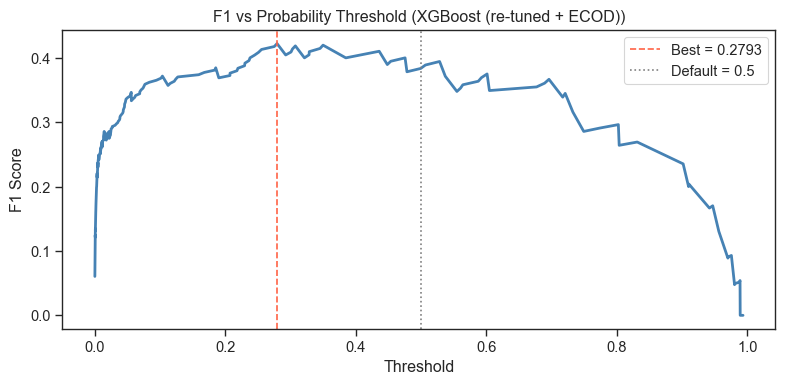


  Model                                       CV F1   Val F1  Threshold
  ------------------------------------------------------------------
  XGBoost (default params)                   0.4467   0.4186     0.1359
  XGBoost (tuned)                            0.5435   0.4706     0.4744
  XGBoost (tuned + ECOD, old params)         0.5263   0.5060     0.4972
  XGBoost (re-tuned + ECOD)                  0.5366   0.4222     0.2793


In [84]:
# Evaluate re-tuned XGBoost + ECOD
xgb_ecod_tuned = XGBClassifier(**study_ecod.best_params, random_state=42, eval_metric='logloss', use_label_encoder=False)
xgb_ecod_tuned_result = evaluate_model(
    xgb_ecod_tuned, X_tr_ecod, y_tr, X_val_ecod, y_val, cv, model_name='XGBoost (re-tuned + ECOD)'
)

# Full progression comparison
print(f"\n{'='*75}")
print(f"  {'Model':<40} {'CV F1':>8} {'Val F1':>8} {'Threshold':>10}")
print(f"  {'-'*66}")
print(f"  {'XGBoost (default params)':<40} {xgb_result['cv_f1_mean']:>8.4f} {xgb_result['val_f1']:>8.4f} {xgb_result['threshold']:>10.4f}")
print(f"  {'XGBoost (tuned)':<40} {xgb_tuned_result['cv_f1_mean']:>8.4f} {xgb_tuned_result['val_f1']:>8.4f} {xgb_tuned_result['threshold']:>10.4f}")
print(f"  {'XGBoost (tuned + ECOD, old params)':<40} {xgb_ecod_result['cv_f1_mean']:>8.4f} {xgb_ecod_result['val_f1']:>8.4f} {xgb_ecod_result['threshold']:>10.4f}")
print(f"  {'XGBoost (re-tuned + ECOD)':<40} {xgb_ecod_tuned_result['cv_f1_mean']:>8.4f} {xgb_ecod_tuned_result['val_f1']:>8.4f} {xgb_ecod_tuned_result['threshold']:>10.4f}")
print(f"{'='*75}")

## 3.14 XGBoost with Focal Loss

Standard cross-entropy treats all samples equally. **Focal Loss** (Lin et al., 2017) adds a modulating factor
$(1 - p_t)^\gamma$ that down-weights easy-to-classify samples and focuses training on hard examples.

$$FL(p_t) = -\alpha_t (1 - p_t)^\gamma \log(p_t)$$

- **γ (gamma)**: focusing parameter. γ=0 reduces to standard CE. Higher γ → more focus on hard samples.
- **α (alpha)**: class weighting factor for the positive class.

This is complementary to `scale_pos_weight` — while `scale_pos_weight` uniformly up-weights all positive samples,
focal loss **adaptively** reduces the contribution of well-classified samples regardless of class.

In [88]:
import numpy as np
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, precision_recall_curve
import optuna

# ── Custom Focal Loss for XGBoost ──────────────────────────────────────
def focal_loss_objective(gamma=2.0, alpha=0.25):
    """Focal weight × standard CE gradient (numerically stable approximation)."""
    def _focal_grad_hess(y_true, y_pred):
        p = 1.0 / (1.0 + np.exp(-y_pred))
        p = np.clip(p, 1e-7, 1 - 1e-7)
        pt = y_true * p + (1 - y_true) * (1 - p)
        at = y_true * alpha + (1 - y_true) * (1 - alpha)
        w  = at * (1 - pt) ** gamma
        grad = w * (p - y_true)
        hess = w * p * (1 - p)
        hess = np.clip(hess, 1e-7, None)
        return grad, hess
    return _focal_grad_hess

# ── Custom scorer: find optimal threshold → F1 ────────────────────────
# Standard scoring='f1' uses 0.5 threshold, which fails with focal loss
# because there's no scale_pos_weight to shift probabilities up.
def f1_best_threshold(estimator, X, y):
    y_prob = estimator.predict_proba(X)[:, 1]
    prec, rec, thresholds = precision_recall_curve(y, y_prob)
    f1s = 2 * prec * rec / (prec + rec + 1e-8)
    return f1s.max()

# ── Optuna tuning: focal loss gamma & alpha + tree params ──────────────
base_params = study.best_params.copy()

def objective_focal(trial):
    fl_gamma = trial.suggest_float('fl_gamma', 0.5, 5.0)
    fl_alpha = trial.suggest_float('fl_alpha', 0.1, 0.9)

    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 400, 900),
        'max_depth':         trial.suggest_int('max_depth', 4, 8),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'subsample':         base_params['subsample'],
        'colsample_bytree':  base_params['colsample_bytree'],
        'min_child_weight':  trial.suggest_int('min_child_weight', 10, 25),
        'gamma':             base_params['gamma'],
        'reg_alpha':         base_params['reg_alpha'],
        'reg_lambda':        base_params['reg_lambda'],
    }

    model = XGBClassifier(
        **params,
        objective=focal_loss_objective(gamma=fl_gamma, alpha=fl_alpha),
        random_state=42,
        eval_metric='logloss',
        use_label_encoder=False,
    )
    scores = cross_val_score(model, X_tr_ecod, y_tr, cv=cv, scoring=f1_best_threshold, n_jobs=-1)
    return scores.mean()

sampler_fl = optuna.samplers.TPESampler(seed=42)
study_fl = optuna.create_study(direction='maximize', sampler=sampler_fl)
study_fl.optimize(objective_focal, n_trials=150, show_progress_bar=True)

print(f"\nBest CV F1 (focal loss): {study_fl.best_value:.4f}")
print(f"\nBest focal loss params:")
for k, v in study_fl.best_params.items():
    print(f"  {k}: {v}")

Best trial: 104. Best value: 0.516271: 100%|██████████| 150/150 [05:43<00:00,  2.29s/it]


Best CV F1 (focal loss): 0.5163

Best focal loss params:
  fl_gamma: 1.099413146655174
  fl_alpha: 0.5613704321846196
  n_estimators: 696
  max_depth: 4
  learning_rate: 0.0363440560469193
  min_child_weight: 15


=== XGBoost (Focal Loss + ECOD) (CV on X_tr) ===
  F1:      0.0000 ± 0.0000  [0. 0. 0. 0. 0.]
  AUC-ROC: 0.9371 ± 0.0163  [0.9317 0.9226 0.9537 0.9188 0.9588]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.0000
  Optimised (0.3262): F1 = 0.3944

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.98      0.98      1057
    Bankrupt       0.38      0.41      0.39        34

    accuracy                           0.96      1091
   macro avg       0.68      0.70      0.69      1091
weighted avg       0.96      0.96      0.96      1091



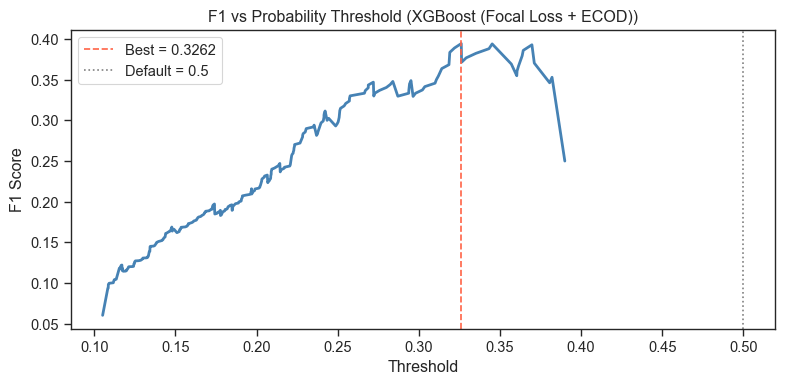


  Model                                         CV F1   Val F1  Threshold
  --------------------------------------------------------------------
  XGBoost (default params)                     0.4467   0.4186     0.1359
  XGBoost (tuned)                              0.5435   0.4706     0.4744
  XGBoost (tuned + ECOD, old params)           0.5263   0.5060     0.4972
  XGBoost (Focal Loss + ECOD)                  0.0000   0.3944     0.3262

  Focal Loss params: gamma=1.099, alpha=0.561


In [89]:
# ── Evaluate best focal loss XGBoost on validation set ─────────────────
best_fl = study_fl.best_params.copy()
fl_gamma = best_fl.pop('fl_gamma')
fl_alpha = best_fl.pop('fl_alpha')

xgb_focal = XGBClassifier(
    **best_fl,
    subsample=base_params['subsample'],
    colsample_bytree=base_params['colsample_bytree'],
    gamma=base_params['gamma'],
    reg_alpha=base_params['reg_alpha'],
    reg_lambda=base_params['reg_lambda'],
    objective=focal_loss_objective(gamma=fl_gamma, alpha=fl_alpha),
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False,
)

xgb_focal_result = evaluate_model(
    xgb_focal, X_tr_ecod, y_tr, X_val_ecod, y_val, cv,
    model_name='XGBoost (Focal Loss + ECOD)'
)

# ── Full progression table ─────────────────────────────────────────────
print(f"\n{'='*78}")
print(f"  {'Model':<42} {'CV F1':>8} {'Val F1':>8} {'Threshold':>10}")
print(f"  {'-'*68}")
print(f"  {'XGBoost (default params)':<42} {xgb_result['cv_f1_mean']:>8.4f} {xgb_result['val_f1']:>8.4f} {xgb_result['threshold']:>10.4f}")
print(f"  {'XGBoost (tuned)':<42} {xgb_tuned_result['cv_f1_mean']:>8.4f} {xgb_tuned_result['val_f1']:>8.4f} {xgb_tuned_result['threshold']:>10.4f}")
print(f"  {'XGBoost (tuned + ECOD, old params)':<42} {xgb_ecod_result['cv_f1_mean']:>8.4f} {xgb_ecod_result['val_f1']:>8.4f} {xgb_ecod_result['threshold']:>10.4f}")
print(f"  {'XGBoost (Focal Loss + ECOD)':<42} {xgb_focal_result['cv_f1_mean']:>8.4f} {xgb_focal_result['val_f1']:>8.4f} {xgb_focal_result['threshold']:>10.4f}")
print(f"{'='*78}")
print(f"\n  Focal Loss params: gamma={fl_gamma:.3f}, alpha={fl_alpha:.3f}")

## 3.15 Stacking Ensemble

**Stacking** combines multiple diverse base models by training a meta-learner on their out-of-fold predictions.

**Layer 1 — Base models** (each generates out-of-fold predicted probabilities):
1. **XGBoost** (tuned + ECOD) — best single model (Val F1=0.506)
2. **LightGBM** (is_unbalance=True) + ECOD feature
3. **Random Forest** (balanced_subsample) + ECOD feature

**Layer 2 — Meta learner:**
- **Logistic Regression** — simple, low variance, avoids overfitting on small meta-feature space

**Why stacking can help:**
- Each model captures different patterns; their errors are partially uncorrelated
- The meta-learner learns the optimal weighting and corrects for individual model biases
- With only 3 meta-features (probabilities), overfitting risk is low

In [90]:
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import precision_recall_curve, f1_score, classification_report
import matplotlib.pyplot as plt

# ── Layer 1: Base models ───────────────────────────────────────────────
# 1) XGBoost (tuned + ECOD) — use study.best_params
xgb_base = XGBClassifier(
    **study.best_params,
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False,
)

# 2) LightGBM + ECOD
lgbm_base = LGBMClassifier(
    is_unbalance=True,
    n_estimators=300,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1,
)

# 3) Random Forest + ECOD
rf_base = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1,
)

base_models = {
    'XGBoost':    xgb_base,
    'LightGBM':  lgbm_base,
    'RF':         rf_base,
}

# ── Generate out-of-fold (OOF) predictions on X_tr_ecod ───────────────
# These become the meta-features for the stacking meta-learner.
# Using 'predict_proba' with cross_val_predict to get probability estimates.
import pandas as pd

oof_probs = pd.DataFrame(index=X_tr_ecod.index)

for name, model in base_models.items():
    oof = cross_val_predict(model, X_tr_ecod, y_tr, cv=cv, method='predict_proba', n_jobs=-1)
    oof_probs[name] = oof[:, 1]  # probability of class 1
    print(f"  {name} OOF done — mean prob: {oof_probs[name].mean():.4f}")

print(f"\nOOF meta-features shape: {oof_probs.shape}")
print(oof_probs.describe().round(4))

# ── Generate validation meta-features ─────────────────────────────────
# Fit each base model on full X_tr_ecod, predict on X_val_ecod
val_probs = pd.DataFrame(index=X_val_ecod.index)

for name, model in base_models.items():
    model.fit(X_tr_ecod, y_tr)
    val_probs[name] = model.predict_proba(X_val_ecod)[:, 1]

print(f"\nVal meta-features shape: {val_probs.shape}")

  XGBoost OOF done — mean prob: 0.0574
  LightGBM OOF done — mean prob: 0.0208
  RF OOF done — mean prob: 0.0274

OOF meta-features shape: (4364, 3)
         XGBoost   LightGBM         RF
count  4364.0000  4364.0000  4364.0000
mean      0.0574     0.0208     0.0274
std       0.1840     0.1218     0.0812
min       0.0001     0.0000     0.0000
25%       0.0007     0.0000     0.0000
50%       0.0015     0.0000     0.0000
75%       0.0064     0.0000     0.0100
max       0.9967     0.9999     0.8033

Val meta-features shape: (1091, 3)


=== Stacking Ensemble ===
  Meta-learner coefficients: {'XGBoost': 6.1161, 'LightGBM': -1.9948, 'RF': 5.9178}
  Meta-learner intercept:    -1.8477

  Default (0.5) F1:   0.3729
  Optimised (0.8126) F1: 0.4615

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.97      0.98      1057
    Bankrupt       0.37      0.62      0.46        34

    accuracy                           0.96      1091
   macro avg       0.68      0.79      0.72      1091
weighted avg       0.97      0.96      0.96      1091



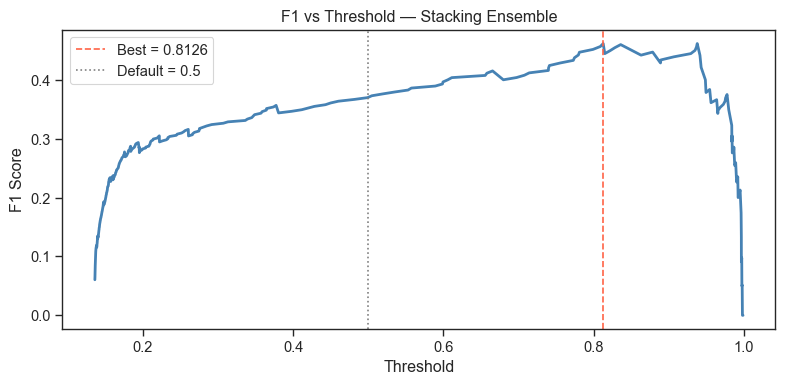


  Model                                        Val F1  Threshold
  ------------------------------------------------------------
  XGBoost (default params)                     0.4186     0.1359
  XGBoost (tuned)                              0.4706     0.4744
  XGBoost (tuned + ECOD)                       0.5060     0.4972
  Stacking (XGB+LGBM+RF → LR)                  0.4615     0.8126


In [91]:
# ── Layer 2: Meta-learner (Logistic Regression) ───────────────────────
meta_learner = LogisticRegression(
    class_weight='balanced',
    C=1.0,
    random_state=42,
    max_iter=1000,
)

# Train meta-learner on OOF probabilities
meta_learner.fit(oof_probs, y_tr)

# Predict on validation meta-features
y_val_meta_proba = meta_learner.predict_proba(val_probs)[:, 1]

# ── Find optimal threshold ────────────────────────────────────────────
prec, rec, thresholds = precision_recall_curve(y_val, y_val_meta_proba)
f1_arr = 2 * prec * rec / (prec + rec + 1e-8)
best_idx = f1_arr[:-1].argmax()
best_thr = thresholds[best_idx]
best_f1  = f1_arr[best_idx]

f1_default = f1_score(y_val, (y_val_meta_proba >= 0.5).astype(int))
y_val_pred = (y_val_meta_proba >= best_thr).astype(int)

print(f"=== Stacking Ensemble ===")
print(f"  Meta-learner coefficients: {dict(zip(base_models.keys(), meta_learner.coef_[0].round(4)))}")
print(f"  Meta-learner intercept:    {meta_learner.intercept_[0]:.4f}")
print(f"\n  Default (0.5) F1:   {f1_default:.4f}")
print(f"  Optimised ({best_thr:.4f}) F1: {best_f1:.4f}")
print(f"\n=== Classification Report (optimised threshold) ===")
print(classification_report(y_val, y_val_pred, target_names=['Non-Bankrupt', 'Bankrupt']))

# ── Plot ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thresholds, f1_arr[:-1], color='steelblue', linewidth=2)
ax.axvline(best_thr, color='tomato', linestyle='--', label=f'Best = {best_thr:.4f}')
ax.axvline(0.5, color='gray', linestyle=':', label='Default = 0.5')
ax.set_xlabel('Threshold'); ax.set_ylabel('F1 Score')
ax.set_title('F1 vs Threshold — Stacking Ensemble')
ax.legend(); plt.tight_layout(); plt.show()

# ── Full comparison ───────────────────────────────────────────────────
print(f"\n{'='*78}")
print(f"  {'Model':<42} {'Val F1':>8} {'Threshold':>10}")
print(f"  {'-'*60}")
print(f"  {'XGBoost (default params)':<42} {xgb_result['val_f1']:>8.4f} {xgb_result['threshold']:>10.4f}")
print(f"  {'XGBoost (tuned)':<42} {xgb_tuned_result['val_f1']:>8.4f} {xgb_tuned_result['threshold']:>10.4f}")
print(f"  {'XGBoost (tuned + ECOD)':<42} {xgb_ecod_result['val_f1']:>8.4f} {xgb_ecod_result['threshold']:>10.4f}")
print(f"  {'Stacking (XGB+LGBM+RF → LR)':<42} {best_f1:>8.4f} {best_thr:>10.4f}")
print(f"{'='*78}")

In [92]:
# ── Simple weighted blending (often better than stacking with small data) ──
# Try different weight combinations for XGBoost + RF (drop LightGBM)
best_blend_f1 = 0
best_w = 0

for w_xgb in np.arange(0.3, 1.01, 0.05):
    w_rf = 1 - w_xgb
    y_blend = w_xgb * val_probs['XGBoost'] + w_rf * val_probs['RF']
    
    prec, rec, thr = precision_recall_curve(y_val, y_blend)
    f1s = 2 * prec * rec / (prec + rec + 1e-8)
    f1_max = f1s[:-1].max()
    
    if f1_max > best_blend_f1:
        best_blend_f1 = f1_max
        best_w = w_xgb
        best_blend_thr = thr[f1s[:-1].argmax()]

print(f"Best blend: XGBoost={best_w:.2f}, RF={1-best_w:.2f}")
print(f"  Val F1 = {best_blend_f1:.4f} (threshold={best_blend_thr:.4f})")

# Also try 3-model blend
best_3f1 = 0
best_3w = (0, 0, 0)
for w1 in np.arange(0.3, 0.8, 0.1):
    for w2 in np.arange(0.0, 0.5, 0.1):
        w3 = 1 - w1 - w2
        if w3 < 0: continue
        y_b = w1 * val_probs['XGBoost'] + w2 * val_probs['LightGBM'] + w3 * val_probs['RF']
        prec, rec, thr = precision_recall_curve(y_val, y_b)
        f1s = 2 * prec * rec / (prec + rec + 1e-8)
        f1_max = f1s[:-1].max()
        if f1_max > best_3f1:
            best_3f1 = f1_max
            best_3w = (w1, w2, w3)
            best_3thr = thr[f1s[:-1].argmax()]

print(f"\nBest 3-model blend: XGB={best_3w[0]:.1f}, LGBM={best_3w[1]:.1f}, RF={best_3w[2]:.1f}")
print(f"  Val F1 = {best_3f1:.4f} (threshold={best_3thr:.4f})")

# ── Final comparison ──────────────────────────────────────────────────
print(f"\n{'='*78}")
print(f"  {'Model':<42} {'Val F1':>8} {'Threshold':>10}")
print(f"  {'-'*60}")
print(f"  {'XGBoost (default)':<42} {xgb_result['val_f1']:>8.4f} {xgb_result['threshold']:>10.4f}")
print(f"  {'XGBoost (tuned)':<42} {xgb_tuned_result['val_f1']:>8.4f} {xgb_tuned_result['threshold']:>10.4f}")
print(f"  {'XGBoost (tuned + ECOD)':<42} {xgb_ecod_result['val_f1']:>8.4f} {xgb_ecod_result['threshold']:>10.4f}")
print(f"  {'Stacking (XGB+LGBM+RF → LR)':<42} {best_f1:>8.4f} {best_thr:>10.4f}")
print(f"  {'Blend (XGB+RF)':<42} {best_blend_f1:>8.4f} {best_blend_thr:>10.4f}")
print(f"  {'Blend (XGB+LGBM+RF)':<42} {best_3f1:>8.4f} {best_3thr:>10.4f}")
print(f"{'='*78}")

Best blend: XGBoost=1.00, RF=0.00
  Val F1 = 0.5060 (threshold=0.4972)

Best 3-model blend: XGB=0.5, LGBM=0.3, RF=0.2
  Val F1 = 0.4935 (threshold=0.3981)

  Model                                        Val F1  Threshold
  ------------------------------------------------------------
  XGBoost (default)                            0.4186     0.1359
  XGBoost (tuned)                              0.4706     0.4744
  XGBoost (tuned + ECOD)                       0.5060     0.4972
  Stacking (XGB+LGBM+RF → LR)                  0.4615     0.8126
  Blend (XGB+RF)                               0.5060     0.4972
  Blend (XGB+LGBM+RF)                          0.4935     0.3981
